# Réduction de modèle pour le problème extérieur de la dérivée topologique

## La question de conception

Une résolution NGSolve donne un champ pour un choix de paramètres. Un **snapshot** est précisément ce champ enregistré pour un point de la grille paramétrique. Nous cherchons une représentation plus courte qui garde la norme physique et qui reste contrôlable sur des points non utilisés pendant l'apprentissage.

Le notebook étudie six configurations de matériaux : `iron_in_air`, `air_in_iron`, `iron_in_air_Bs`, `magnet_in_iron`, `iron_in_magnet` et `nonlinear_magnet_in_nonlinear_magnet`. Elles utilisent le même maillage et la même norme. L'ordre des matériaux compte parce que l'inclusion et le domaine extérieur n'ont pas le même rôle dans la forme faible : inverser les deux lois change le saut de matériau, la solution et les spectres.

Le parcours est unique : problème et solveur NGSolve, six jeux de snapshots, POD/SVD pondérée, convergence en nombre de snapshots, CP/PARAFAC pour les cas multiparamétriques, coût mémoire puis NeuROM appris par une loss physique. Chaque diagnostic répond à une question distincte et reste vérifié hors grille.

## Repères de reproduction du rapport

Le rapport cite cinq identifiants recherchables dans ce fichier : `R1_VALIDATION` (solveur, maillage et contrôles), `R2_SNAPSHOTS` (six banques de données), `R3_POD` (POD, convergence en $P$ et hors-grille), `R4_CP` (CP/ALS et interpolation), `R5_NEUROM` (énergie, apprentissage et évaluation). Pour reproduire un résultat isolé sans état caché, exécuter d'abord toutes les cellules précédentes ; la procédure recommandée reste **Restart Kernel and Run All Cells**.


## 0. Imports


In [1]:
import os, sys, io, contextlib, importlib.metadata as metadata
import numpy as np, matplotlib.pyplot as plt, time
import torch
import torch.nn as nn
# NeuROM 4.0.6 affiche un avertissement optionnel lié à tikzplotlib à l'import.
with contextlib.redirect_stdout(io.StringIO()):
    import neurom.HiDeNN_PDE as neurom_pde
    from neurom.HiDeNN_PDE import NeuROM
import ngsolve as ng
from netgen.occ import Circle, Glue, OCCGeometry
from ngsolve.solvers import Newton

ng.ngsglobals.msg_level = 0
plt.rcParams['text.usetex'] = False
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

NU0, ORDER = 1.0, 2
torch.set_default_dtype(torch.float64)
torch.manual_seed(7)
np.random.seed(7)
print('Python', sys.version.split()[0], '| NumPy', np.__version__,
      '| Matplotlib', metadata.version('matplotlib'))
print('NGSolve', ng.__version__, '| PyTorch', torch.__version__,
      '| neurom-py', metadata.version('neurom-py'),
      '| TensorLy', metadata.version('tensorly'))


Python 3.11.5 | NumPy 2.4.6 | Matplotlib 3.11.1
NGSolve 6.2.2606 | PyTorch 2.14.0 | neurom-py 4.0.6 | TensorLy 0.9.0


## 1. Paramètres et problème extérieur

Les paramètres sont séparés de la géométrie et de l'inconnue :

| famille | objet | rôle dans cette étude |
|---|---|---|
| inconnue | $K:\mathbb{R}^2\to\mathbb{R}$ | correcteur scalaire |
| quantité observée | $\operatorname{curl}K=(\partial_yK,-\partial_xK)$ | champ physique stocké |
| géométrie | $\omega$ disque unité, $R$ rayon de troncature | fixée, puis contrôlée numériquement |
| matériau | $\nu_{\rm in},\nu_{\rm out},m$ | lois choisies ci-dessous |
| paramètres $\mu$ | $B_0,\theta_m,B_s$ | axes échantillonnés |

Pour toute fonction test $\varphi$, on résout la forme faible de Gangl–Sturm,
éq. 2.31 :

$$
\int_{\mathbb{R}^2}\operatorname{curl}\varphi\cdot
[h_\omega(b_0+\operatorname{curl}K)-h_\omega(b_0)]
=-\int_\omega\operatorname{curl}\varphi\cdot
[h_{\rm in}(b_0)-h_{\rm out}(b_0)].
$$

En non-linéaire, $b_0$ intervient dans les deux membres ; le point $z$ de la
machine agit donc ici via la valeur de $b_0$. Le modèle isotrope et le disque sont
invariants par rotation : on fixe $\theta_0=0$, et avec un aimant on conserve
l'angle relatif $\theta_m-\theta_0$.


## 2. Lois $B$-$H$

On écrit $h(b)=\nu(|b|)b-m$. L'air est linéaire, l'aimant ajoute $m$, et le
fer est modélisé par quatre familles monotones :

$$\nu(s)=\nu_{\min}+(\nu_0-\nu_{\min})f(r),\qquad
r=(s/B_{\rm sat})^\alpha.
$$

| nom | $f(r)$ | lecture |
|---|---|---|
| rationnelle (type Marrocco) | $r/(1+r)$ | convention du notebook collègue |
| arctan | $2\arctan(r)/\pi$ | coude plus progressif |
| exponentielle | $1-\exp(-r)$ | transition plus rapide |
| algébrique | $r/\sqrt{1+r^2}$ | saturation plus lente |

La première forme reprend la convention rationnelle utilisée dans le notebook
originel comme **approximation de type Marrocco**. Elle ne prétend pas être une
courbe industrielle calibrée ni l'autre paramétrisation Marrocco présente ailleurs
dans le dépôt ; la comparaison porte ici sur la robustesse qualitative de la
réduction. On vérifie directement que $B\mapsto H(B)=\nu(B)B$ est croissante.


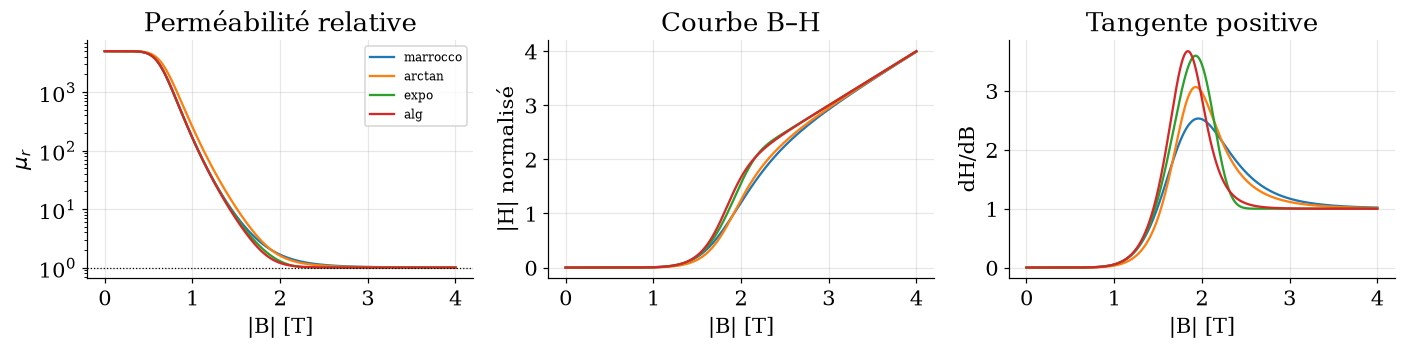

Monotonie vérifiée pour les quatre lois.


In [2]:
NU_FE, B_SAT, ALPHA = NU0 / 5000., 1.9, 8.

def nu_iron(s2, law='marrocco', Bs=B_SAT):
    r = (s2 / Bs**2)**(ALPHA / 2)
    fun = (ng.sqrt, ng.atan, ng.exp) if isinstance(s2, ng.CF) else (np.sqrt, np.arctan, np.exp)
    sqrt, atan, exp = fun
    f = {'marrocco': r/(1+r), 'arctan': (2/np.pi)*atan(r),
         'expo': 1-exp(-r), 'alg': r/sqrt(1+r*r)}[law]
    return NU_FE + (NU0 - NU_FE)*f

LAWS = ['marrocco', 'arctan', 'expo', 'alg']
s = np.linspace(1e-6, 4., 20000)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for law in LAWS:
    nu = nu_iron(s**2, law)
    H = nu*s
    assert np.all(np.diff(H) > 0), f'{law}: H(B) non monotone'
    ax[0].semilogy(s, NU0/nu, label=law)
    ax[1].plot(s, H, label=law)
    ax[2].plot(s[:-1], np.diff(H)/np.diff(s), label=law)
ax[0].axhline(1, ls=':', c='k', lw=.8)
ax[0].set(xlabel='|B| [T]', ylabel=r'$\mu_r$', title='Perméabilité relative')
ax[1].set(xlabel='|B| [T]', ylabel='|H| normalisé', title='Courbe B–H')
ax[2].set(xlabel='|B| [T]', ylabel='dH/dB', title='Tangente positive')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Monotonie vérifiée pour les quatre lois.')

## 3. Solveur NGSolve et visualisation

Le disque unité est plongé dans un grand disque $B_R$, avec $K=0$ sur le bord
extérieur. En 2D,
$\operatorname{curl}u=(\partial_yu,-\partial_xu)$. La forme non linéaire est
assemblée directement dans BilinearForm, puis la boucle de Newton est fournie
par NGSolve. $R$ et la taille de maille sont des réglages numériques.


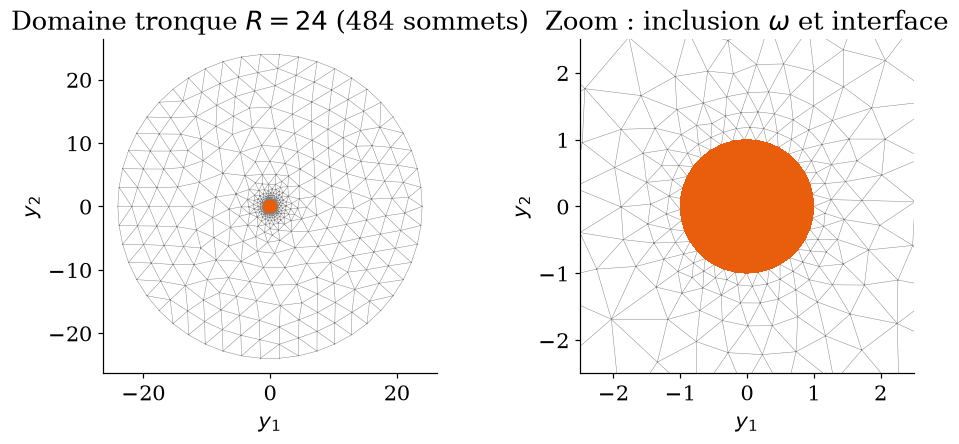

Maillage de demonstration : 484 sommets, 916 triangles.


In [3]:
def make_mesh(R=24., h_far=None, h_int=.16, order=ORDER):
    out, inc = Circle((0, 0), R).Face(), Circle((0, 0), 1.).Face()
    out.edges.name, inc.edges.maxh = 'outer', h_int
    bg = out - inc
    bg.faces.name, inc.faces.name = 'out', 'inc'
    geo = OCCGeometry(Glue([bg, inc]), dim=2)
    mesh = ng.Mesh(geo.GenerateMesh(maxh=h_far or max(R/8, 1.)))
    mesh.Curve(order + 1)
    return mesh


curl = lambda u: ng.CF((ng.grad(u)[1], -ng.grad(u)[0]))


def h_air():
    return lambda b: NU0*b


def h_lin(mur=5000.):
    return lambda b: (NU0/mur)*b


def h_iron(law='marrocco', Bs=B_SAT):
    return lambda b: nu_iron(ng.InnerProduct(b, b) + 1e-18, law, Bs)*b


def h_magnet(M, theta):
    return lambda b: NU0*b - ng.CF((M*ng.cos(theta), M*ng.sin(theta)))


NU_PM, B_SAT_PM, ALPHA_PM = NU0/10., 3., 3.


def nu_pm(s2):
    r = (s2/B_SAT_PM**2)**(ALPHA_PM/2)
    return NU_PM + (NU0-NU_PM)*r/(1+r)


def h_magnet_nl(M, theta):
    c, s = ng.cos(theta), ng.sin(theta)

    def law(b):
        bp, bt = c*b[0] + s*b[1], -s*b[0] + c*b[1]
        hp, ht = nu_pm(bp*bp + 1e-18)*bp, NU0*bt
        return ng.CF((c*hp - s*ht - M*c, s*hp + c*ht - M*s))

    return law


def solve_corrector(mesh, h_in, h_out, b0, order=ORDER):
    fes = ng.H1(mesh, order=order, dirichlet='outer')
    K = ng.GridFunction(fes)
    u, v = fes.TnT()
    b = ng.CF(b0)
    cu, cv = curl(u), curl(v)

    form = ng.BilinearForm(fes, symmetric=True)
    form += ng.InnerProduct(h_in(b+cu) - h_in(b), cv)*ng.dx('inc')
    form += ng.InnerProduct(h_out(b+cu) - h_out(b), cv)*ng.dx('out')
    form += ng.InnerProduct(h_in(b) - h_out(b), cv)*ng.dx('inc')

    failed, iterations = Newton(form, K, inverse='sparsecholesky',
                                printing=False, maxit=80)
    assert failed == 0, f'Newton a echoue pour b0={b0}'
    return K, iterations


def mean_curl(K, mesh):
    area = ng.Integrate(ng.CF(1), mesh, definedon=mesh.Materials('inc'))
    total = ng.Integrate(curl(K), mesh, definedon=mesh.Materials('inc'))
    return np.asarray(total)/area


def plot_mesh(mesh, ax, zoom=None):
    '''Trace les aretes du maillage ; l'inclusion est coloree.'''
    xy = np.array([v.point for v in mesh.vertices])
    tri = np.array([[v.nr for v in el.vertices] for el in mesh.Elements()])
    inc = np.array([el.mat == 'inc' for el in mesh.Elements()])
    ax.triplot(xy[:, 0], xy[:, 1], tri, lw=.3, color='0.5')
    ax.tripcolor(xy[:, 0], xy[:, 1], tri[inc], facecolors=np.ones(inc.sum()),
                 cmap='Oranges', vmin=0, vmax=1.5)
    ax.set(aspect='equal', xlabel='$y_1$', ylabel='$y_2$')
    ax.grid(False)
    if zoom:
        ax.set(xlim=(-zoom, zoom), ylim=(-zoom, zoom))


demo = make_mesh()
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
plot_mesh(demo, ax[0])
ax[0].set_title(f'Domaine tronque $R=24$ ({demo.nv} sommets)')
plot_mesh(demo, ax[1], zoom=2.5)
ax[1].set_title("Zoom : inclusion $\\omega$ et interface")
plt.tight_layout()
plt.show()

print(f'Maillage de demonstration : {demo.nv} sommets, {demo.ne} triangles.')

### 3.1 À quoi ressemble $K$ et $|\operatorname{curl}K|$

Ces cartes montrent pourquoi on stocke le champ vectoriel $\operatorname{curl}K$
plutôt que le potentiel seul. Le champ de fond est horizontal ; le dernier panneau
montre la perte d'uniformité dans l'inclusion quand le fer sature.


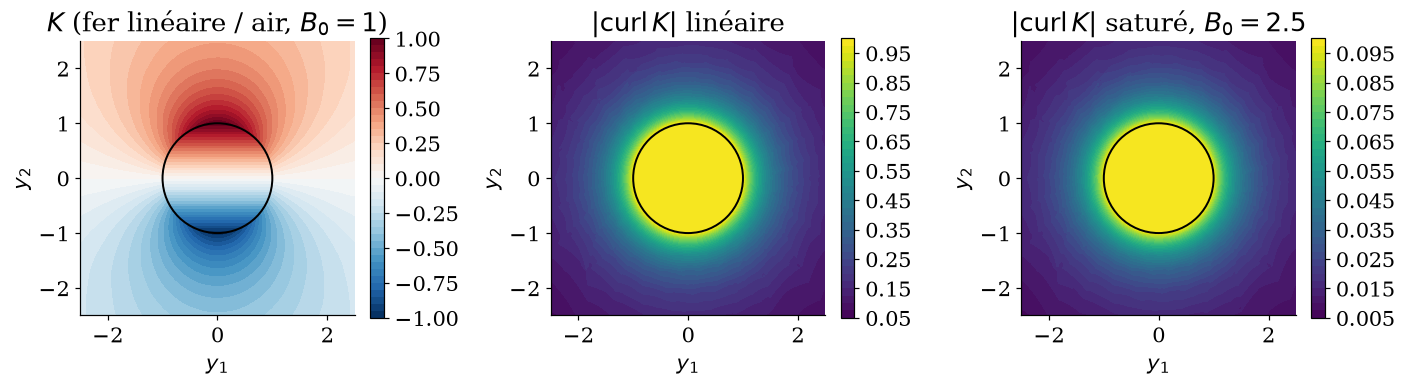

In [4]:
def plot_field(ax, mesh, cf, title, n=180, R=2.5, vsym=False, bounds=None):
    grid = np.linspace(-R, R, n)
    X, Y = np.meshgrid(grid, grid)
    pts = mesh(X.ravel(), Y.ravel())
    Z = np.asarray(cf(pts)).reshape(n, n)
    kw = {'cmap': 'RdBu_r', 'vmin': -np.abs(Z).max(), 'vmax': np.abs(Z).max()} if vsym else {'cmap': 'viridis'}
    if bounds is not None: kw.update(vmin=bounds[0], vmax=bounds[1])
    levels = np.linspace(*bounds, 41) if bounds is not None else 40
    im = ax.contourf(X, Y, Z, levels, **kw)
    ax.add_artist(plt.Circle((0, 0), 1, fill=False, color='k', lw=1.3))
    ax.set(aspect='equal', title=title, xlabel='$y_1$', ylabel='$y_2$')
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=.046)

demo_mesh = make_mesh(R=20., h_int=.08)
K_lin, _ = solve_corrector(demo_mesh, h_lin(), h_air(), (1., 0.))
K_nl, _ = solve_corrector(demo_mesh, h_iron(), h_air(), (2.5, 0.))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.7))
plot_field(ax[0], demo_mesh, K_lin, r'$K$ (fer linéaire / air, $B_0=1$)', vsym=True)
plot_field(ax[1], demo_mesh, ng.sqrt(ng.InnerProduct(curl(K_lin), curl(K_lin))), r'$|\operatorname{curl}K|$ linéaire')
plot_field(ax[2], demo_mesh, ng.sqrt(ng.InnerProduct(curl(K_nl), curl(K_nl))), r'$|\operatorname{curl}K|$ saturé, $B_0=2.5$')
plt.tight_layout()
plt.show()


## 4. Validation linéaire et saturation

Pour deux matériaux linéaires et une inclusion circulaire, la solution analytique
donne

$$\operatorname{curl}K|_\omega=\alpha b_0,\qquad
\alpha=\frac{\nu_{\rm out}-\nu_{\rm in}}{\nu_{\rm out}+\nu_{\rm in}}.
$$

C'est un test de signes, de curl, de maillage et de troncature. Le modèle linéaire
est aussi homogène en $b_0$, alors que la saturation introduit une dépendance en
$B_0$.


Fer dans air      : alpha analytique = +0.999600 | NGSolve = +0.995549 | erreur = 4.05e-03
Air dans fer      : alpha analytique = -0.999600 | NGSolve = -0.999599 | erreur = 1.21e-06
Contraste nul     : ||curl K||^2 = 0.00e+00
Erreur de troncature : R=6 : 5.44e-02 | R=9 : 2.48e-02 | R=12 : 1.42e-02 | R=16 : 8.30e-03 | R=24 : 4.05e-03 | R=32 : 2.54e-03


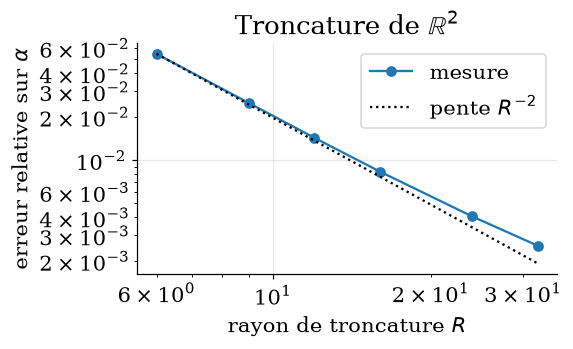

In [5]:
# [R1_VALIDATION] Contrôles analytique, troncature et saturation.
R_TRUNC = np.array([6., 9., 12., 16., 24., 32.])
ALPHA_REF = (NU0 - NU0/5000.)/(NU0 + NU0/5000.)


def truncation_test(radii=R_TRUNC):
    '''Erreur relative sur alpha en fonction du rayon de troncature.'''
    errors = []
    for R in radii:
        m = make_mesh(R=float(R), h_int=.16)
        K, _ = solve_corrector(m, h_lin(), h_air(), (1., 0.))
        errors.append(abs(mean_curl(K, m)[0]/ALPHA_REF - 1))
    return np.array(errors)


trunc_err = truncation_test()
alpha_ref = ALPHA_REF

# Reference analytique, dans les deux sens d'inclusion.
check_mesh = make_mesh(R=24., h_int=.16)
K, _ = solve_corrector(check_mesh, h_lin(), h_air(), (1., 0.))
alpha_num = mean_curl(K, check_mesh)[0]
K_rev, _ = solve_corrector(check_mesh, h_air(), h_lin(), (1., 0.))
alpha_rev_num = mean_curl(K_rev, check_mesh)[0]

print(f'Fer dans air      : alpha analytique = {alpha_ref:+.6f} | '
      f'NGSolve = {alpha_num:+.6f} | erreur = {abs(alpha_num/alpha_ref-1):.2e}')
print(f'Air dans fer      : alpha analytique = {-alpha_ref:+.6f} | '
      f'NGSolve = {alpha_rev_num:+.6f} | '
      f'erreur = {abs(alpha_rev_num/(-alpha_ref)-1):.2e}')
assert abs(alpha_num/alpha_ref-1) < 5e-3
assert abs(alpha_rev_num/(-alpha_ref)-1) < 5e-3

# Sans contraste de materiau, le correcteur doit etre nul.
K0, _ = solve_corrector(check_mesh, h_air(), h_air(), (1.5, 0.))
zero = ng.Integrate(ng.InnerProduct(curl(K0), curl(K0)), check_mesh)
print(f'Contraste nul     : ||curl K||^2 = {zero:.2e}')
assert zero < 1e-18

print('Erreur de troncature : '
      + ' | '.join(f'R={R:.0f} : {e:.2e}' for R, e in zip(R_TRUNC, trunc_err)))

fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.loglog(R_TRUNC, trunc_err, 'o-', label='mesure')
ax.loglog(R_TRUNC, trunc_err[0]*(R_TRUNC/R_TRUNC[0])**-2., 'k:',
          label=r'pente $R^{-2}$')
ax.set(xlabel='rayon de troncature $R$',
       ylabel=r'erreur relative sur $\alpha$',
       title=r'Troncature de $\mathbb{R}^2$')
ax.legend()
plt.tight_layout()
plt.show()

### 4.1 Robustesse qualitative au choix de la loi

Les quatre lois sont comparées à réglage identique. On ne cherche pas à départager
des courbes industrielles ; on vérifie que le mécanisme de saturation et le
diagnostic de réduction ne dépendent pas d'une formule particulière.


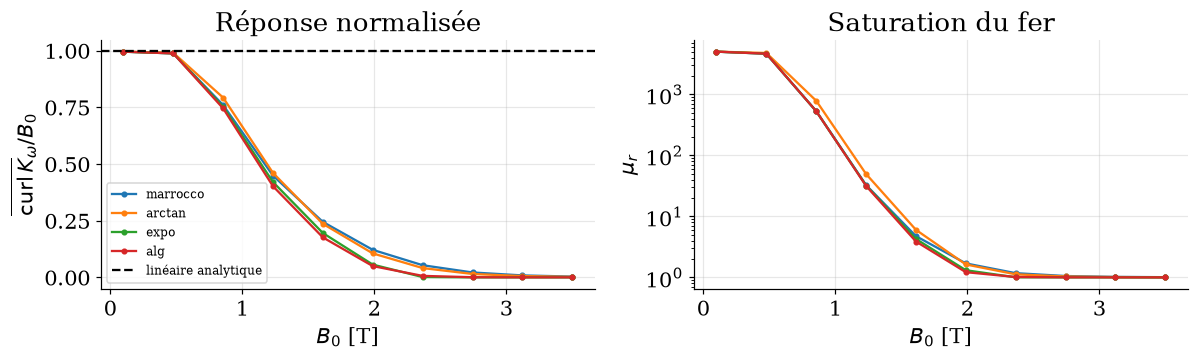

Les quatre lois décrochent avec la saturation ; les rangs seront comparés sur la loi rationnelle.


In [6]:
sat_mesh = make_mesh(R=24., h_int=.16)
B_sat_test = np.linspace(.1, 3.5, 10)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for law in LAWS:
    response = [mean_curl(solve_corrector(sat_mesh, h_iron(law), h_air(), (float(B), 0.))[0], sat_mesh)[0]/B
                for B in B_sat_test]
    ax[0].plot(B_sat_test, response, 'o-', ms=3, label=law)
    ax[1].semilogy(B_sat_test, [NU0/nu_iron(B**2, law) for B in B_sat_test], 'o-', ms=3, label=law)
ax[0].axhline(alpha_ref, ls='--', c='k', label='linéaire analytique')
ax[0].set(xlabel='$B_0$ [T]', ylabel=r'$\overline{\operatorname{curl}K}_\omega/B_0$', title='Réponse normalisée')
ax[1].set(xlabel='$B_0$ [T]', ylabel='$\\mu_r$', title='Saturation du fer')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Les quatre lois décrochent avec la saturation ; les rangs seront comparés sur la loi rationnelle.')


## 5. Des snapshots au tenseur paramétrique

Chaque résolution EF donne un champ discrétisé $q(x,\mu)=\operatorname{curl}K$. En rangeant l'espace et les paramètres sur des axes séparés :

$$\mathcal{Q} \in \mathbb{R}^{N\times n_1\times\cdots\times n_d}$$

où $n_j$ est le nombre de valeurs du paramètre $j$, et $N$ la dimension spatiale. La matrice de snapshots $S \in \mathbb{R}^{N\times P}$, avec $P=\prod_j n_j$, est ce même tenseur déplié : **une colonne = un champ complet pour un jeu de paramètres**.

**La dimension spatiale $N$.** Le champ $\operatorname{curl}K$ est stocké dans un espace `VectorL2` d'ordre 1 :

$$N = \underbrace{2}_{\text{composantes}} \times \underbrace{3}_{\text{ddl par triangle}} \times \underbrace{916}_{\text{triangles}} = 5496$$

**Trois diagnostics complémentaires**, du plus permissif au plus contraignant :

| section | question posée | contrainte |
|---|---|---|
| 5.2 POD | combien de **formes spatiales** ? | aucune sur les paramètres |
| 5.3 étude en $P$ | le résultat tient-il quand la grille s'affine ? | — |
| 5.4 PARAFAC | peut-on **séparer chaque paramètre** ? | un facteur par axe |

In [7]:
STUDY_MESH = make_mesh(R=24., h_int=.16)
VL2 = ng.VectorL2(STUDY_MESH, order=ORDER-1)
FIELD = ng.GridFunction(VL2)
q, r = VL2.TnT()
MASS = ng.BilinearForm(VL2)
MASS += ng.InnerProduct(q, r)*ng.dx
MASS.Assemble()
def snapshot(h_in, h_out, b0):
    K, _ = solve_corrector(STUDY_MESH, h_in, h_out, b0)
    FIELD.Set(curl(K))
    return FIELD.vec.FV().NumPy().copy()
def mass_product(x):
    src, dst = ng.BaseVector(VL2.ndof), ng.BaseVector(VL2.ndof)
    src.FV().NumPy()[:] = x
    MASS.mat.Mult(src, dst)
    return dst.FV().NumPy().copy()
def l2_norm(x): return np.sqrt(max(float(x @ mass_product(x)), 0.))

TOLS = (.05, .02, .01, .001)
def weighted_pod(S):
    S = np.asarray(S)
    MS = np.column_stack([mass_product(S[:, j]) for j in range(S.shape[1])])
    G = .5*(S.T @ MS + MS.T @ S)
    values, vectors = np.linalg.eigh(G)
    order = np.argsort(values)[::-1]
    values, vectors = np.maximum(values[order], 0.), vectors[:, order]
    sigma = np.sqrt(values)
    energy = values.sum()
    residual = np.sqrt(np.maximum(energy - np.cumsum(values), 0.)/energy)
    ranks = {tol: int(np.flatnonzero(residual <= tol)[0]+1) if np.any(residual <= tol) else len(sigma) for tol in TOLS}
    keep = sigma > sigma[0]*1e-10
    Phi = (S @ vectors[:, keep]) / sigma[keep]
    return sigma, residual, ranks, Phi, MS
def print_ranks(name, pod, P):
    print(f'{name}: P={P} | ' + ' | '.join(f'r({tol:.1%})={pod[2][tol]}' for tol in TOLS))


### 5.1 Grilles et six études explicites

Nous fixons six familles de solutions. Une étude correspond à une configuration physique et à ses paramètres ; elle possède une seule grille fine de référence. Les niveaux plus petits de l'étude en $P$ sont des sous-grilles emboîtées de cette grille fine. Cette organisation évite de compter deux fois un même cas et permet de réutiliser exactement les mêmes snapshots pour POD, $P$ et PARAFAC.

| Cas | Matériau dans l'inclusion | Matériau extérieur | Paramètres |
|---|---|---|---|
| `iron_in_air` | fer non linéaire | air | $B_0$ |
| `air_in_iron` | air | fer non linéaire | $B_0$ |
| `iron_in_air_Bs` | fer non linéaire, $B_s$ variable | air | $B_0,B_s$ |
| `magnet_in_iron` | aimant uniforme | fer non linéaire | $B_0,\theta_m$ |
| `iron_in_magnet` | fer non linéaire | aimant uniforme | $B_0,\theta_m$ |
| `nonlinear_magnet_in_nonlinear_magnet` | aimant non linéaire | aimant non linéaire | $B_0,\theta_{in},\theta_{out}$ |

Les deux premiers cas servent de contrôle à un seul paramètre. Les quatre suivants ont au moins deux paramètres. Les angles sont périodiques : on n'ajoute donc pas artificiellement la valeur $2\pi$\, identique à $0$.

In [8]:
# [R2_SNAPSHOTS] Définition et calcul des six banques de snapshots.
M_REM = 1.2
B_SINGLE = np.linspace(.2, 3.2, 9)
B_BS = B_SINGLE.copy()
BS_FINE = np.linspace(1.2, 3.2, 5)
B_ANGULAR = B_SINGLE.copy()
THETA_ANGULAR = np.linspace(0., 2*np.pi, 16, endpoint=False)
B_3D = np.linspace(.5, 3.0, 5)
THETA_3D = np.linspace(0., 2*np.pi, 8, endpoint=False)

STUDY_CASES = ('iron_in_air', 'air_in_iron', 'iron_in_air_Bs', 'magnet_in_iron', 'iron_in_magnet', 'nonlinear_magnet_in_nonlinear_magnet')
STUDY_AXES_FINE = {
    'iron_in_air': (B_SINGLE,), 'air_in_iron': (B_SINGLE,),
    'iron_in_air_Bs': (B_BS, BS_FINE),
    'magnet_in_iron': (B_ANGULAR, THETA_ANGULAR),
    'iron_in_magnet': (B_ANGULAR, THETA_ANGULAR),
    'nonlinear_magnet_in_nonlinear_magnet': (B_3D, THETA_3D, THETA_3D),
}
STUDY_PARAMETER_NAMES = {
    'iron_in_air': ('B0',), 'air_in_iron': ('B0',), 'iron_in_air_Bs': ('B0', 'Bs'),
    'magnet_in_iron': ('B0', 'theta_m'), 'iron_in_magnet': ('B0', 'theta_m'),
    'nonlinear_magnet_in_nonlinear_magnet': ('B0', 'theta_in', 'theta_out'),
}
STUDY_SOLVERS = {
    'iron_in_air': lambda p: snapshot(h_iron(), h_air(), (p[0], 0.)),
    'air_in_iron': lambda p: snapshot(h_air(), h_iron(), (p[0], 0.)),
    'iron_in_air_Bs': lambda p: snapshot(h_iron(Bs=p[1]), h_air(), (p[0], 0.)),
    'magnet_in_iron': lambda p: snapshot(h_magnet(M_REM, p[1]), h_iron(), (p[0], 0.)),
    'iron_in_magnet': lambda p: snapshot(h_iron(), h_magnet(M_REM, p[1]), (p[0], 0.)),
    'nonlinear_magnet_in_nonlinear_magnet': lambda p: snapshot(h_magnet_nl(M_REM, p[1]), h_magnet_nl(.6*M_REM, p[2]), (p[0], 0.)),
}
t_snap = time.perf_counter()
STUDY_SNAPSHOTS = {}
for case in STUDY_CASES:
    fields = [STUDY_SOLVERS[case](tuple(float(x) for x in point)) for point in __import__('itertools').product(*STUDY_AXES_FINE[case])]
    STUDY_SNAPSHOTS[case] = np.column_stack(fields)
STUDY_PODS = {case: weighted_pod(STUDY_SNAPSHOTS[case]) for case in STUDY_CASES}
print(f'snapshots : {time.perf_counter()-t_snap:.1f} s | six études | ' + ' | '.join(f'{case}: P={STUDY_SNAPSHOTS[case].shape[1]}' for case in STUDY_CASES))
for case in STUDY_CASES: print_ranks(case, STUDY_PODS[case], STUDY_SNAPSHOTS[case].shape[1])

snapshots : 29.1 s | six études | iron_in_air: P=9 | air_in_iron: P=9 | iron_in_air_Bs: P=45 | magnet_in_iron: P=144 | iron_in_magnet: P=144 | nonlinear_magnet_in_nonlinear_magnet: P=320
iron_in_air: P=9 | r(5.0%)=1 | r(2.0%)=1 | r(1.0%)=1 | r(0.1%)=1
air_in_iron: P=9 | r(5.0%)=3 | r(2.0%)=4 | r(1.0%)=5 | r(0.1%)=7
iron_in_air_Bs: P=45 | r(5.0%)=1 | r(2.0%)=1 | r(1.0%)=1 | r(0.1%)=1
magnet_in_iron: P=144 | r(5.0%)=11 | r(2.0%)=20 | r(1.0%)=31 | r(0.1%)=76
iron_in_magnet: P=144 | r(5.0%)=2 | r(2.0%)=2 | r(1.0%)=2 | r(0.1%)=2
nonlinear_magnet_in_nonlinear_magnet: P=320 | r(5.0%)=18 | r(2.0%)=34 | r(1.0%)=49 | r(0.1%)=120


### 5.1.1 Tableau des jeux de données

Chaque ligne désigne une étude et une seule grille fine. $P$ est le nombre de snapshots, c'est-à-dire le produit des nombres de points sur les axes paramétriques. Les mêmes champs peuvent être vus comme une matrice $N\times P$, ou comme un tenseur $N\times n_1\times\cdots\times n_d$.

| Étude | Paramètres | Grille fine | $P$ |
|---|---|---:|---:|
| `iron_in_air` | $B_0$ | $9$ | $9$ |
| `air_in_iron` | $B_0$ | $9$ | $9$ |
| `iron_in_air_Bs` | $B_0,B_s$ | $9\times5$ | $45$ |
| `magnet_in_iron` | $B_0,\theta_m$ | $9\times16$ | $144$ |
| `iron_in_magnet` | $B_0,\theta_m$ | $9\times16$ | $144$ |
| `nonlinear_magnet_in_nonlinear_magnet` | $B_0,\theta_{in},\theta_{out}$ | $5\times8\times8$ | $320$ |

La dimension spatiale est $N=5496$ dans le VectorL2 utilisé pour stocker $\operatorname{curl}K$.

### 5.2 POD : combien de formes spatiales ?

On place les $P$ snapshots en colonnes de $S \in \mathbb{R}^{N\times P}$ et l'on cherche la meilleure base spatiale de taille $r$ :

$$q(x,\mu) \;\approx\; \sum_{k=1}^{r} \Phi_k(x)\, c_k(\mu)$$

**Ce que la POD sépare, et ce qu'elle ne sépare pas.** Elle sépare l'espace $x$ du bloc de *tous* les paramètres pris ensemble : le coefficient $c_k(\mu)$ reste une fonction **quelconque** de $\mu=(\mu_1,\ldots,\mu_d)$. Elle ne dit donc rien sur la séparabilité *entre* les paramètres — c'est l'objet de la section 5.4.

La POD mesure ici une seule chose : la **dimension de la famille de solutions**, c'est-à-dire le nombre de formes spatiales nécessaires. Le résidu après $r$ modes, en norme de masse EF, vaut

$$\varepsilon_{\mathrm{POD}}(r) = \left(\frac{\sum_{k>r}\sigma_k^2}{\sum_k \sigma_k^2}\right)^{1/2}$$

Les seuils de $5\%$ et $2\%$ sont des repères numériques sur la grille fine.

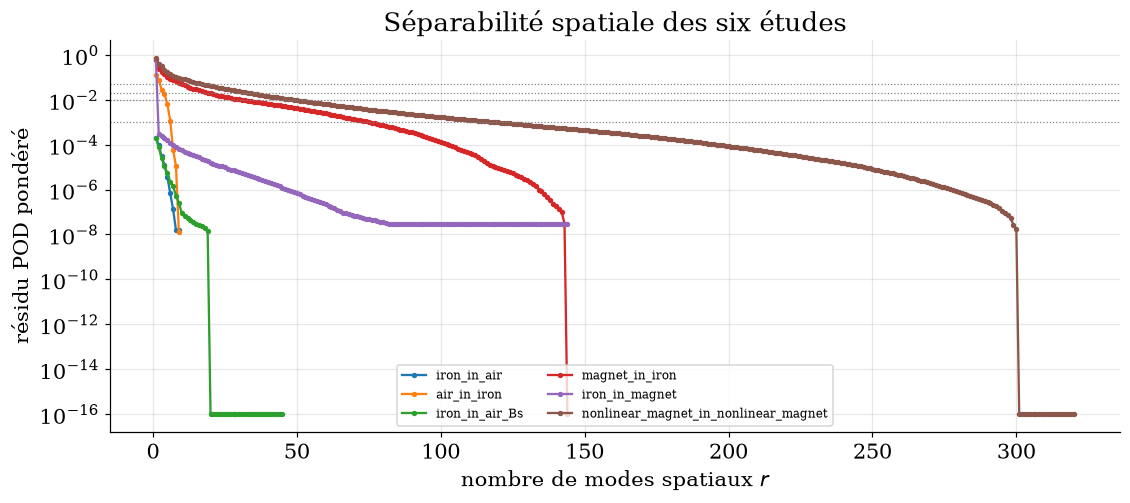

Étude | P | r(5 %) | r(2 %) | r(1 %) | r(0,1 %)
iron_in_air 9 1 1 1 1
air_in_iron 9 3 4 5 7
iron_in_air_Bs 45 1 1 1 1
magnet_in_iron 144 11 20 31 76
iron_in_magnet 144 2 2 2 2
nonlinear_magnet_in_nonlinear_magnet 320 18 34 49 120


In [9]:
# [R3_POD] Spectres et rangs POD sur les grilles fines.
POD_CASES = [(case, STUDY_PODS[case]) for case in STUDY_CASES]
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for case, (sigma, residual, _, _, _) in POD_CASES:
    ranks = np.arange(1, len(residual)+1)
    ax.semilogy(ranks, np.maximum(residual, 1e-16),
                'o-', ms=2.5, label=case)
for tol in TOLS:
    ax.axhline(tol, ls=':', lw=.8, color='gray')
ax.set(xlabel='nombre de modes spatiaux $r$',
       ylabel='résidu POD pondéré',
       title='Séparabilité spatiale des six études')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

print('Étude | P | r(5 %) | r(2 %) | r(1 %) | r(0,1 %)')
for case, pod in POD_CASES:
    print(case, STUDY_SNAPSHOTS[case].shape[1],
          *(pod[2][tol] for tol in TOLS))


### 5.3 — Vérifier la convergence quand $P$ augmente

Un faible rang observé sur une grille pauvre peut être trompeur. Nous reprenons les six études avec des grilles emboîtées, toujours dans le même domaine paramétrique et avec la même masse EF : $B_0$ seul utilise $3,5,9$ points ; `iron_in_air_Bs` utilise $3\times3,5\times3,9\times5$ ; les cas angulaires utilisent $3\times4,5\times8,9\times16$ ; le cas à trois paramètres utilise $2\times2\times2,3\times4\times4,5\times8\times8$.

Le dernier niveau est exactement la grille fine de la section 5.1. Les holdouts sont fixés une fois pour chaque cas, à l'intérieur du domaine mais hors de la grille fine ; ils ne changent donc pas quand $P$ augmente.


In [10]:
from itertools import product

def parameter_key(*values):
    return tuple(round(float(value), 12) for value in values)

def nested_axes(axes, sizes, periodic_axes=None):
    """Select nested points; periodic axes use exact stride subgrids."""
    if periodic_axes is None:
        periodic_axes = (False,) * len(axes)
    result = []
    for axis, n, periodic in zip(axes, sizes, periodic_axes):
        axis = np.asarray(axis)
        if periodic:
            if len(axis) % n != 0:
                raise ValueError('une grille périodique doit être divisible par n')
            result.append(axis[::len(axis)//n][:n])
        else:
            result.append(axis[np.linspace(0, len(axis)-1, n, dtype=int)])
    return tuple(result)

def database_from_study(case):
    return {parameter_key(*point): field
            for point, field in zip(product(*STUDY_AXES_FINE[case]),
                                    STUDY_SNAPSHOTS[case].T)}

def matrix_from_axes(db, axes):
    return np.column_stack([db[parameter_key(*point)] for point in product(*axes)])

def pod_level(S):
    sigma, residual, ranks, Phi, MS = weighted_pod(S)
    return {'S': S, 'sigma': sigma, 'residual': residual,
            'ranks': ranks, 'Phi': Phi, 'MS': MS}

P_LEVEL_SIZES = {
    'iron_in_air': ((3,), (5,), (9,)),
    'air_in_iron': ((3,), (5,), (9,)),
    'iron_in_air_Bs': ((3,3), (5,3), (9,5)),
    'magnet_in_iron': ((3,4), (5,8), (9,16)),
    'iron_in_magnet': ((3,4), (5,8), (9,16)),
    'nonlinear_magnet_in_nonlinear_magnet': ((2,2,2), (3,4,4), (5,8,8)),
}
P_PERIODIC_AXES = {
    'iron_in_air': (False,), 'air_in_iron': (False,),
    'iron_in_air_Bs': (False, False),
    'magnet_in_iron': (False, True), 'iron_in_magnet': (False, True),
    'nonlinear_magnet_in_nonlinear_magnet': (False, True, True),
}
P_LEVEL_LABELS = {
    case: tuple('x'.join(map(str, size)) for size in sizes)
    for case, sizes in P_LEVEL_SIZES.items()
}
P_CASES = STUDY_CASES

# Jeu de contrôle commun, généré avant l'étude en P pour éviter tout changement
# de protocole entre POD, P, CP et NeuROM.
HOLDOUT_COUNT = 32
HOLDOUT_SEED = 20260916

def latin_hypercube_holdout(case, count=HOLDOUT_COUNT, seed=HOLDOUT_SEED):
    """Tire count points dans le domaine, sans réutiliser de nœud d'apprentissage."""
    axes = STUDY_AXES_FINE[case]
    periodic = P_PERIODIC_AXES[case]
    rng = np.random.default_rng(seed + 1009 * STUDY_CASES.index(case))
    unit = np.empty((count, len(axes)))
    for j, (axis, is_periodic) in enumerate(zip(axes, periodic)):
        perm = rng.permutation(count)
        jitter = rng.uniform(.1, .9, size=count)
        unit[:, j] = (perm + jitter) / count
        if is_periodic:
            unit[:, j] %= 1.
    points = []
    for row in unit:
        point = []
        for u, axis, is_periodic in zip(row, axes, periodic):
            axis = np.asarray(axis, dtype=float)
            if is_periodic:
                value = float((2*np.pi*u) % (2*np.pi))
            else:
                value = float(axis[0] + u*(axis[-1] - axis[0]))
            if np.any(np.isclose(value, axis, rtol=0., atol=1e-12)):
                value = float(value + (axis[-1] - axis[0])/(count*1000))
                if is_periodic:
                    value %= 2*np.pi
            point.append(value)
        points.append(tuple(point))
    return points

OUTSIDE = {case: latin_hypercube_holdout(case) for case in STUDY_CASES}
OUTSIDE_REFS = {
    case: [STUDY_SOLVERS[case](point) for point in OUTSIDE[case]]
    for case in STUDY_CASES
}


Les 32 points de contrôle sont générés une seule fois avant l'étude en $P$, par Latin hypercube avec la graine fixée $20260916$. Ils sont réutilisés à tous les niveaux de $P$ et dans les sections POD, CP et NeuROM. Les angles sont périodiques et le point $2\pi$ n'est jamais dupliqué.


In [11]:
def projection_error(ref, Phi):
    projection = Phi @ (Phi.T @ mass_product(ref))
    return float(l2_norm(ref - projection) / l2_norm(ref))

def threshold_holdout_errors(levels, refs):
    result = {}
    for label, info in levels.items():
        result[label] = {}
        for tol in (.05, .02):
            Phi = info['Phi'][:, :info['ranks'][tol]]
            errors = [projection_error(ref, Phi) for ref in refs]
            result[label][tol] = {'max': float(np.max(errors)), 'mean': float(np.mean(errors))}
    return result

# [R3_POD] Convergence en nombre de snapshots sur les mêmes points hors grille.
P_CONVERGENCE = {}
t_p_study = time.perf_counter()
for case in P_CASES:
    db = database_from_study(case)
    levels = {}
    for label, sizes in zip(P_LEVEL_LABELS[case], P_LEVEL_SIZES[case]):
        axes = nested_axes(STUDY_AXES_FINE[case], sizes, P_PERIODIC_AXES[case])
        levels[label] = pod_level(matrix_from_axes(db, axes))
    points = OUTSIDE[case]
    refs = OUTSIDE_REFS[case]
    errors = threshold_holdout_errors(levels, refs)
    P_CONVERGENCE[case] = {'levels': levels, 'points': points, 'refs': refs, 'errors': errors}
    print('\n'+case)
    for label, info in levels.items():
        e2=errors[label][.02]
        print(f"{label}: P={info['S'].shape[1]} | r5={info['ranks'][.05]} | r2={info['ranks'][.02]} | holdout r2 max/moy={e2['max']:.2%}/{e2['mean']:.2%}")
print(f'campagne de convergence en P : {time.perf_counter()-t_p_study:.1f} s | holdouts partagés={HOLDOUT_COUNT}')



iron_in_air
3: P=3 | r5=1 | r2=1 | holdout r2 max/moy=0.05%/0.02%
5: P=5 | r5=1 | r2=1 | holdout r2 max/moy=0.03%/0.03%
9: P=9 | r5=1 | r2=1 | holdout r2 max/moy=0.04%/0.03%

air_in_iron
3: P=3 | r5=2 | r2=2 | holdout r2 max/moy=23.68%/10.90%
5: P=5 | r5=3 | r2=3 | holdout r2 max/moy=12.64%/4.27%
9: P=9 | r5=3 | r2=4 | holdout r2 max/moy=6.29%/2.95%

iron_in_air_Bs
3x3: P=9 | r5=1 | r2=1 | holdout r2 max/moy=0.03%/0.02%
5x3: P=15 | r5=1 | r2=1 | holdout r2 max/moy=0.04%/0.02%
9x5: P=45 | r5=1 | r2=1 | holdout r2 max/moy=0.04%/0.02%

magnet_in_iron
3x4: P=12 | r5=6 | r2=7 | holdout r2 max/moy=30.17%/12.30%
5x8: P=40 | r5=9 | r2=15 | holdout r2 max/moy=12.70%/4.50%
9x16: P=144 | r5=11 | r2=20 | holdout r2 max/moy=10.33%/2.97%

iron_in_magnet
3x4: P=12 | r5=2 | r2=2 | holdout r2 max/moy=0.05%/0.03%
5x8: P=40 | r5=2 | r2=2 | holdout r2 max/moy=0.04%/0.03%
9x16: P=144 | r5=2 | r2=2 | holdout r2 max/moy=0.04%/0.03%

nonlinear_magnet_in_nonlinear_magnet
2x2x2: P=8 | r5=3 | r2=4 | holdout r2 

Une conclusion est crédible lorsque le résidu, le rang au seuil de $2\%$ et l'erreur hors grille se stabilisent entre les deux derniers niveaux. On compare ici la **dimension spatiale** de la famille échantillonnée ; la séparation entre axes paramétriques est traitée en 5.4.

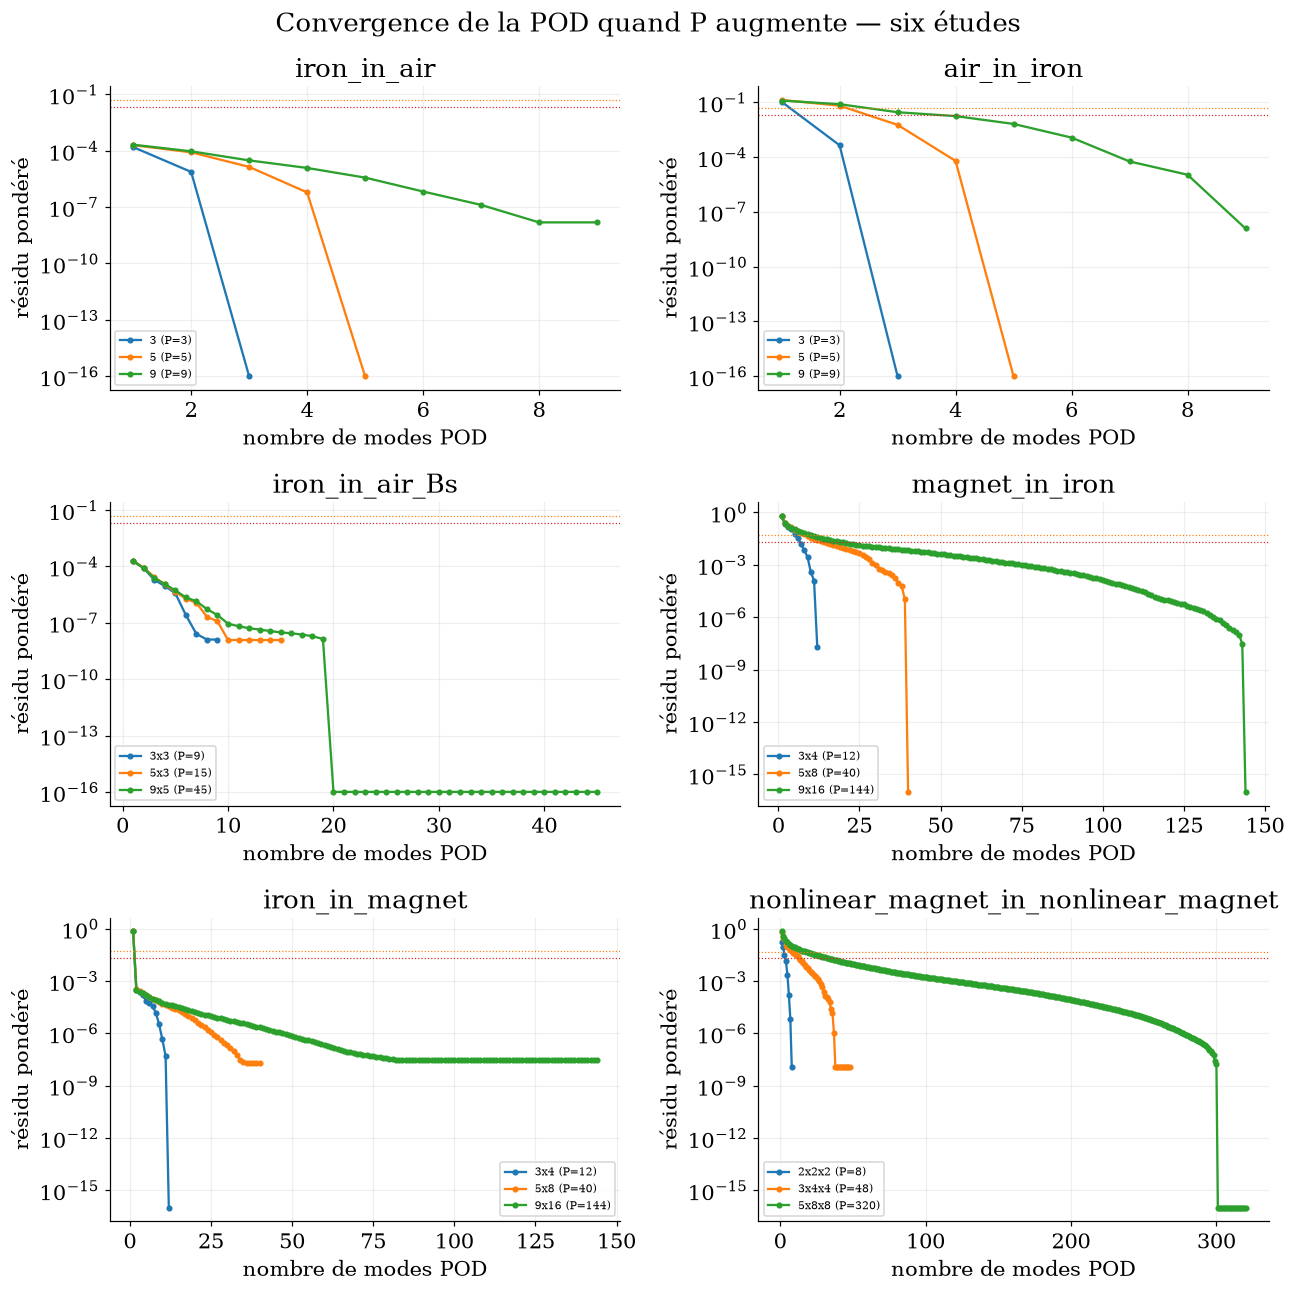

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharey=False)
for ax, case in zip(axes.flat, P_CASES):
    for label, info in P_CONVERGENCE[case]['levels'].items():
        P = info['S'].shape[1]
        ax.semilogy(np.arange(1, len(info['residual'])+1), np.maximum(info['residual'],1e-16), 'o-', ms=3, label=f'{label} (P={P})')
    ax.axhline(.05, color='tab:orange', ls=':', lw=.8)
    ax.axhline(.02, color='tab:red', ls=':', lw=.8)
    ax.set(title=case, xlabel='nombre de modes POD', ylabel='résidu pondéré')
    ax.legend(fontsize=7)
    ax.grid(True, which='both', alpha=.2)
fig.suptitle('Convergence de la POD quand P augmente — six études')
fig.tight_layout()
plt.show()

Rangs et erreurs relevés au dernier niveau de chaque étude :

| Cas | niveaux $P$ | rang 5 % : début $\to$ fin | rang 2 % : début $\to$ fin | max holdout au rang 2 % final |
|---|---:|---:|---:|---:|
| `iron_in_air` | 3, 5, 9 | 1 $\to$ 1 | 1 $\to$ 1 | 0,04 % |
| `air_in_iron` | 3, 5, 9 | 2 $\to$ 3 | 2 $\to$ 4 | 6,29 % |
| `iron_in_air_Bs` | $3\times3$, $5\times3$, $9\times5$ | 1 $\to$ 1 | 1 $\to$ 1 | 0,04 % |
| `magnet_in_iron` | $3\times4$, $5\times8$, $9\times16$ | 5 $\to$ 11 | 7 $\to$ 20 | 10,33 % |
| `iron_in_magnet` | $3\times4$, $5\times8$, $9\times16$ | 2 $\to$ 2 | 2 $\to$ 2 | 0,04 % |
| `nonlinear_magnet_in_nonlinear_magnet` | $2^3$, $3\times4^2$, $5\times8^2$ | 3 $\to$ 18 | 4 $\to$ 34 | 8,11 % |

Les points de contrôle sont identiques aux trois niveaux. Une stabilisation est un indice de couverture suffisante, pas une preuve de convergence uniforme.

Deux lectures s'opposent nettement : `iron_in_air` et `iron_in_air_Bs` restent de rang $1$ quelle que soit la grille, tandis que `magnet_in_iron` et le cas à trois paramètres voient leur rang tripler entre le premier et le dernier niveau. Un rang faible mesuré sur une grille grossière n'est donc pas exploitable tel quel.

### 5.4 PARAFAC : séparer aussi les paramètres entre eux

**L'idée.** La POD autorise un coefficient $c_k(\mu_1,\mu_2)$ quelconque. PARAFAC (ou CP, *Canonical Polyadic*) impose **un facteur par paramètre** :

$$q(x,\mu_1,\mu_2) \;\approx\; \sum_{r=1}^{R} X_r(x)\,F_r(\mu_1)\,G_r(\mu_2)$$

C'est la généralisation de la SVD aux tenseurs, et la contrainte est **strictement plus forte** que celle de la POD : toute décomposition CP est une décomposition POD, jamais l'inverse. On a donc toujours $R \ge r$.

**Pourquoi c'est la bonne mesure ici.** Cette forme est exactement celle que cherche la PGD (section 6). Mesurer $R$ sur les snapshots dit donc, *avant* d'implémenter quoi que ce soit, si la PGD a une chance d'aboutir.

Sous forme générale, pour $d$ paramètres :

$$\widehat{\mathcal{Q}}_R = \sum_{r=1}^{R} x_r \circ f_r^{(1)} \circ\cdots\circ f_r^{(d)}$$

**Attention** : les $R$ termes ne sont **pas** des valeurs singulières. CP n'offre pas de suite canonique décroissante, donc on ne peut pas choisir le rang sans calculer la reconstruction pour chaque $R$ — d'où la boucle sur les rangs. Le calcul se fait dans les coordonnées POD, l'erreur étant ramenée à la norme de masse EF.

Conventions : [Kolda & Bader (2009)](https://doi.org/10.1137/07070111X), [documentation TensorLy](https://tensorly.org/dev/modules/generated/tensorly.decomposition.parafac.html).

In [13]:
def count_free_dofs(fes):
    free = fes.FreeDofs()
    return int(sum(bool(free[i]) for i in range(fes.ndof)))
H1_STUDY = ng.H1(STUDY_MESH, order=ORDER, dirichlet='outer')
SPATIAL_DIMS = {'sommets maillage': int(STUDY_MESH.nv), 'H1 ndof': int(H1_STUDY.ndof), 'H1 libres': count_free_dofs(H1_STUDY), 'VectorL2 ndof N': int(VL2.ndof)}
print('Dimensions spatiales exactes :', SPATIAL_DIMS)

Dimensions spatiales exactes : {'sommets maillage': 484, 'H1 ndof': 1883, 'H1 libres': 1783, 'VectorL2 ndof N': 5496}


#### 5.4.1 Erreur mesurée dans la norme EF

La base POD $\Phi$ est $M$-orthonormale : $\Phi^\top M \Phi = I$. Pour chaque grille, on calcule les coordonnées $C = \Phi^\top M S$, puis on remet $C$ sous la forme $(r_{\text{POD}}, n_1, \ldots, n_d)$. Si $\widehat{C}_R$ est la reconstruction CP,

$$\varepsilon_M(R)^2 = \frac{\lVert S\rVert_M^2 - \lVert C\rVert_F^2 + \lVert C - \widehat{C}_R\rVert_F^2}{\lVert S\rVert_M^2}$$

Le premier terme est le plancher POD, le second l'erreur de séparation CP. Diagnostic *a posteriori* sur les snapshots : ce n'est pas encore un apprentissage NeuROM.

In [14]:
from tensorly.decomposition import parafac
from tensorly.cp_tensor import cp_to_tensor
def pod_info_as_tuple(info): return (info['sigma'], info['residual'], info['ranks'], info['Phi'], info['MS'])
def cp_total_error(S, dims, pod, rank, n_init=3, max_iter=300, tol=1e-8, seed0=123):
    Phi, MS = pod[3], pod[4]
    C_flat = Phi.T @ MS
    C = C_flat.reshape((Phi.shape[1],)+tuple(dims))
    total2 = float(np.sum(S*MS))
    coords2 = float(np.sum(C*C))
    floor2 = max(total2-coords2,0.)
    starts=[('svd',None)]+[('random',seed0+j) for j in range(n_init-1)]
    best=None
    for init, seed in starts:
        actual=init if (init!='svd' or rank<=min(C.shape)) else 'random'
        actual_seed=(seed if seed is not None else seed0) if actual=='random' else None
        cp, errors=parafac(C, rank=rank, init=actual, random_state=actual_seed, n_iter_max=max_iter, tol=tol, normalize_factors=False, return_errors=True)
        err2=float(np.sum((C-cp_to_tensor(cp))**2))
        total=np.sqrt(max(floor2+err2,0.)/total2)
        if best is None or total<best['total_error']:
            best={'total_error':total,'cp_error':np.sqrt(err2/max(coords2,1e-30)),
                  'init':actual,'als_iterations':len(errors),
                  'converged': len(errors) < max_iter}
    best['pod_floor']=np.sqrt(floor2/total2)
    return best


#### 5.4.2 Étude compacte en $P$

PARAFAC est appliquée aux quatre études multiparamétriques. On réutilise les trois niveaux déjà construits dans `P_CONVERGENCE`, sans calculer de nouveaux snapshots. Chaque rang utilise un départ SVD lorsque possible et un départ aléatoire ; le meilleur résidu est conservé. Le nombre d'itérations ALS est imprimé pour repérer les ajustements qui atteignent la limite de calcul. Les repères 5 % et 2 % sont les mêmes que pour la POD.


In [15]:
CP_CASES = (
    'iron_in_air_Bs', 'magnet_in_iron', 'iron_in_magnet',
    'nonlinear_magnet_in_nonlinear_magnet',
)
CP_RANKS = {
    'iron_in_air_Bs': (1, 2, 3, 5, 8, 12),
    'magnet_in_iron': (1, 2, 3, 5, 8, 12, 16, 24, 32),
    'iron_in_magnet': (1, 2, 3, 5, 8, 12, 16, 24, 32),
    'nonlinear_magnet_in_nonlinear_magnet': (1, 2, 3, 5, 8, 12, 16, 24),
}
# [R4_CP] Balayage CP/ALS sur les quatre cas multiparamétriques.
CP_RESULTS = {}
t_cp = time.perf_counter()
for case in CP_CASES:
    CP_RESULTS[case] = {}
    for label, info in P_CONVERGENCE[case]['levels'].items():
        sizes = P_LEVEL_SIZES[case][P_LEVEL_LABELS[case].index(label)]
        rows = []
        for rank in CP_RANKS[case]:
            if rank > info['S'].shape[1]:
                continue
            fit = cp_total_error(info['S'], sizes,
                                 pod_info_as_tuple(info), rank,
                                 n_init=3, max_iter=300)
            rows.append({
                'rank': rank,
                'error': fit['total_error'],
                'init': fit['init'],
                'als_iterations': fit['als_iterations'],
                'converged': fit['converged'],
            })
        CP_RESULTS[case][label] = rows
        print(f'{case} | {label} | ' + ' | '.join(
            f"R={row['rank']}: {row['error']:.2%} "
            f"({row['als_iterations']} ALS, converged={row['converged']})"
            for row in rows))
print(f'campagne CP/PARAFAC sur trois niveaux : {time.perf_counter()-t_cp:.1f} s')

iron_in_air_Bs | 3x3 | R=1: 19.17% (2 ALS, converged=True) | R=2: 8.10% (8 ALS, converged=True) | R=3: 0.02% (3 ALS, converged=True) | R=5: 0.00% (229 ALS, converged=True) | R=8: 0.00% (103 ALS, converged=True)
iron_in_air_Bs | 5x3 | R=1: 21.47% (2 ALS, converged=True) | R=2: 6.14% (6 ALS, converged=True) | R=3: 0.02% (3 ALS, converged=True) | R=5: 0.01% (295 ALS, converged=True) | R=8: 0.00% (56 ALS, converged=True) | R=12: 0.00% (36 ALS, converged=True)


iron_in_air_Bs | 9x5 | R=1: 22.76% (2 ALS, converged=True) | R=2: 5.70% (5 ALS, converged=True) | R=3: 1.00% (5 ALS, converged=True) | R=5: 0.01% (300 ALS, converged=False) | R=8: 0.01% (72 ALS, converged=True) | R=12: 0.00% (236 ALS, converged=True)


magnet_in_iron | 3x4 | R=1: 70.75% (5 ALS, converged=True) | R=2: 34.86% (5 ALS, converged=True) | R=3: 15.64% (75 ALS, converged=True) | R=5: 6.36% (300 ALS, converged=False) | R=8: 3.10% (300 ALS, converged=False) | R=12: 0.00% (5 ALS, converged=True)


magnet_in_iron | 5x8 | R=1: 65.21% (5 ALS, converged=True) | R=2: 33.37% (5 ALS, converged=True) | R=3: 19.67% (44 ALS, converged=True) | R=5: 11.15% (300 ALS, converged=False) | R=8: 6.48% (300 ALS, converged=False) | R=12: 4.12% (300 ALS, converged=False) | R=16: 2.77% (300 ALS, converged=False) | R=24: 1.23% (300 ALS, converged=False) | R=32: 0.37% (300 ALS, converged=False)


magnet_in_iron | 9x16 | R=1: 62.73% (4 ALS, converged=True) | R=2: 31.15% (5 ALS, converged=True) | R=3: 20.03% (47 ALS, converged=True) | R=5: 11.53% (300 ALS, converged=False) | R=8: 7.40% (300 ALS, converged=False) | R=12: 5.51% (300 ALS, converged=False) | R=16: 4.00% (300 ALS, converged=False) | R=24: 2.53% (300 ALS, converged=False) | R=32: 1.73% (300 ALS, converged=False)


iron_in_magnet | 3x4 | R=1: 68.87% (2 ALS, converged=True) | R=2: 18.93% (3 ALS, converged=True) | R=3: 2.08% (3 ALS, converged=True) | R=5: 0.11% (300 ALS, converged=False) | R=8: 0.01% (300 ALS, converged=False) | R=12: 0.00% (10 ALS, converged=True)


iron_in_magnet | 5x8 | R=1: 68.19% (2 ALS, converged=True) | R=2: 21.76% (3 ALS, converged=True) | R=3: 4.95% (3 ALS, converged=True) | R=5: 0.59% (3 ALS, converged=True) | R=8: 0.05% (300 ALS, converged=False) | R=12: 0.02% (300 ALS, converged=False) | R=16: 0.01% (300 ALS, converged=False) | R=24: 0.00% (300 ALS, converged=False) | R=32: 0.00% (112 ALS, converged=True)


iron_in_magnet | 9x16 | R=1: 67.83% (2 ALS, converged=True) | R=2: 20.76% (3 ALS, converged=True) | R=3: 5.09% (3 ALS, converged=True) | R=5: 1.06% (3 ALS, converged=True) | R=8: 0.15% (3 ALS, converged=True) | R=12: 0.03% (300 ALS, converged=False) | R=16: 0.02% (300 ALS, converged=False) | R=24: 0.01% (300 ALS, converged=False) | R=32: 0.00% (300 ALS, converged=False)


nonlinear_magnet_in_nonlinear_magnet | 2x2x2 | R=1: 41.17% (4 ALS, converged=True) | R=2: 14.76% (183 ALS, converged=True) | R=3: 7.66% (268 ALS, converged=True) | R=5: 1.91% (300 ALS, converged=False) | R=8: 0.00% (3 ALS, converged=True)


nonlinear_magnet_in_nonlinear_magnet | 3x4x4 | R=1: 75.30% (5 ALS, converged=True) | R=2: 56.50% (16 ALS, converged=True) | R=3: 41.06% (300 ALS, converged=False) | R=5: 25.27% (300 ALS, converged=False) | R=8: 9.92% (300 ALS, converged=False) | R=12: 5.95% (300 ALS, converged=False) | R=16: 3.71% (300 ALS, converged=False) | R=24: 2.14% (300 ALS, converged=False)


nonlinear_magnet_in_nonlinear_magnet | 5x8x8 | R=1: 80.74% (5 ALS, converged=True) | R=2: 62.59% (300 ALS, converged=False) | R=3: 45.91% (300 ALS, converged=False) | R=5: 38.01% (300 ALS, converged=False) | R=8: 26.06% (300 ALS, converged=False) | R=12: 17.47% (300 ALS, converged=False) | R=16: 13.47% (300 ALS, converged=False) | R=24: 10.33% (300 ALS, converged=False)
campagne CP/PARAFAC sur trois niveaux : 11.8 s


#### 5.4.3 Lire les résultats

Une décroissance rapide avec $R$ signifie que le tenseur discrétisé est bien approché par peu de produits espace-paramètres. Une décroissance lente indique que les paramètres restent fortement couplés à l'espace ou entre eux. La POD laisse les paramètres libres dans chaque coefficient, tandis que CP impose un facteur pour chaque axe. Les trois niveaux permettent de vérifier que le résultat CP n'est pas un artefact d'un petit $P$. Les erreurs restent des reconstructions sur grille. Le contrôle hors grille de la section 5.6 vérifie les bases POD, mais il ne valide pas une interpolation des facteurs CP entre leurs nœuds.


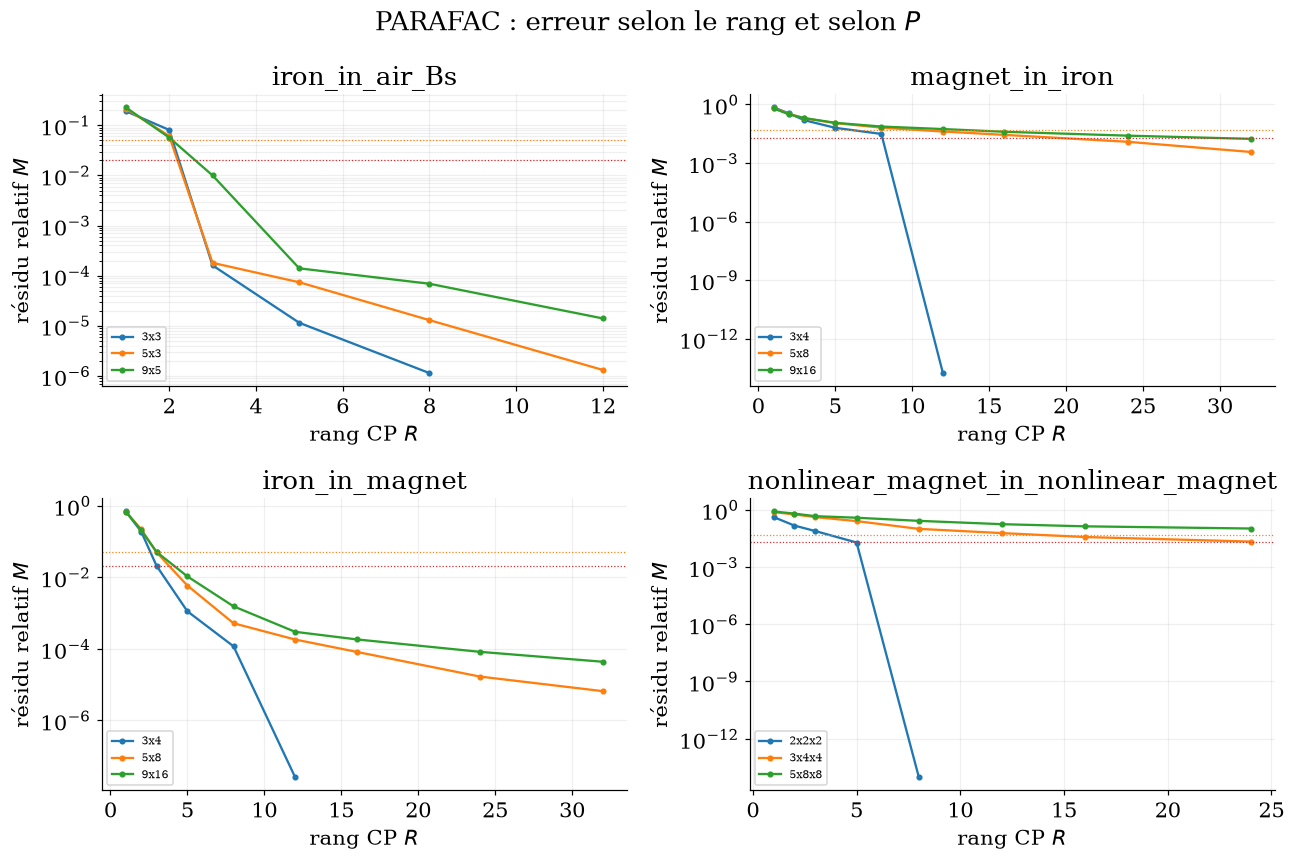

Cas | niveau | premier R sous 5 % | premier R sous 2 % | ALS convergée
iron_in_air_Bs 3x3 3 3 True
iron_in_air_Bs 5x3 3 3 True
iron_in_air_Bs 9x5 3 3 True
magnet_in_iron 3x4 8 12 True
magnet_in_iron 5x8 12 24 False
magnet_in_iron 9x16 16 32 False
iron_in_magnet 3x4 3 5 False
iron_in_magnet 5x8 3 5 True
iron_in_magnet 9x16 5 5 True
nonlinear_magnet_in_nonlinear_magnet 2x2x2 5 5 False
nonlinear_magnet_in_nonlinear_magnet 3x4x4 16 None None
nonlinear_magnet_in_nonlinear_magnet 5x8x8 None None None


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=False)
for ax, case in zip(axes.flat, CP_CASES):
    for label, rows_cp in CP_RESULTS[case].items():
        ax.semilogy([row['rank'] for row in rows_cp],
                    [row['error'] for row in rows_cp],
                    'o-', ms=3, label=label)
    ax.axhline(.05, ls=':', lw=.8, color='tab:orange')
    ax.axhline(.02, ls=':', lw=.8, color='tab:red')
    ax.set(title=case, xlabel='rang CP $R$', ylabel='résidu relatif $M$')
    ax.grid(True, which='both', alpha=.2)
    ax.legend(fontsize=7)
fig.suptitle('PARAFAC : erreur selon le rang et selon $P$')
fig.tight_layout()
plt.show()

print('Cas | niveau | premier R sous 5 % | premier R sous 2 % | ALS convergée')
for case in CP_CASES:
    for label, rows_cp in CP_RESULTS[case].items():
        r5 = next((row['rank'] for row in rows_cp if row['error'] <= .05), None)
        r2 = next((row['rank'] for row in rows_cp if row['error'] <= .02), None)
        selected = next((row for row in rows_cp if row['rank'] == r2), None)
        converged = None if selected is None else selected['converged']
        print(case, label, r5, r2, converged)


Le rang CP n'est pas une valeur singulière : on retient le premier $R$ dont l'erreur de reconstruction passe sous le seuil, lorsqu'il est dans le budget testé.

Sur les grilles fines :

| Cas | grille fine | premier $R$ sous $5\%$ | premier $R$ sous $2\%$ | erreur au dernier rang |
|---|---:|---:|---:|---:|
| `iron_in_air_Bs` | $9\times5$ | $3$ | $3$ | $0{,}00\%$ à $R=12$ |
| `magnet_in_iron` | $9\times16$ | $16$ | $32$ | $1{,}73\%$ à $R=32$ |
| `iron_in_magnet` | $9\times16$ | $5$ | $5$ | $1{,}06\%$ à $R=32$ |
| `nonlinear_magnet_in_nonlinear_magnet` | $5\times8\times8$ | non atteint | non atteint | $10{,}33\%$ à $R=24$ |

**Réserve importante.** Pour `magnet_in_iron` et le cas à trois paramètres, l'ALS atteint la limite de $300$ itérations sans converger. « Seuil non atteint » signifie donc *à budget d'itérations fixé*, ce qui n'est pas la même affirmation que « le rang CP est élevé ». Seuls `iron_in_air_Bs` ($R=3$) et `iron_in_magnet` ($R=5$) atteignent leur seuil avec une ALS convergée.

### 5.5 Stockage : la compression est-elle réelle ?

Les sections précédentes donnent des **rangs**. Celle-ci les traduit en **nombre de coefficients à stocker**, seule façon de répondre à « est-ce que ça comprime vraiment ? »

Trois tailles spatiales à ne pas confondre : $484$ sommets de maillage, $1783$ ddl $H^1$ libres pour le potentiel $K$, et $N=5496$ coefficients `VectorL2` pour le champ $\operatorname{curl}K$. Un sommet n'est pas un coefficient de champ.

| représentation | coefficients stockés |
|---|---|
| snapshots bruts | $NP$ |
| POD de rang $r$ | $r\,(N+P)$ |
| CP de rang $R$ | $R\left(N+\sum_j n_j+1\right)$ |
| NeuROM de rang $R$ | $R\left(N_{H^1}+\sum_j n_j\right)$ |

Le **facteur de compression** est le rapport $NP$ / stockage du modèle : au-dessus de $1$, la représentation tient en moins de coefficients que la banque de snapshots, à la précision annoncée.

La POD stocke $r$ champs plus leurs coordonnées ; CP remplace les coordonnées par des facteurs $1$-D, bien plus légers, mais au prix d'un rang plus élevé. NeuROM compte dans l'espace $H^1$ du potentiel et non dans `VectorL2` : son facteur est donc indicatif et n'est pas directement comparable aux deux autres.

In [17]:
N_VEC = SPATIAL_DIMS['VectorL2 ndof N']
N_H1_FREE = SPATIAL_DIMS['H1 libres']
N_VERTICES = SPATIAL_DIMS['sommets maillage']
print('Repères spatiaux :', N_VERTICES, 'sommets |',
      N_H1_FREE, 'ddl H1 libres |', N_VEC, 'coefficients VectorL2')

def first_rank_below(rows, threshold):
    return next((row['rank'] for row in rows
                 if row['error'] <= threshold), None)

CP_FINE_RANKS = {}
for case in CP_CASES:
    case_fine_rows = CP_RESULTS[case][P_LEVEL_LABELS[case][-1]]
    CP_FINE_RANKS[case] = (
        first_rank_below(case_fine_rows, .05),
        first_rank_below(case_fine_rows, .02),
    )

STORAGE_ROWS = []
for case in STUDY_CASES:
    axes = STUDY_AXES_FINE[case]
    P = int(np.prod([len(axis) for axis in axes]))
    r_selected = STUDY_PODS[case][2][.02]
    r_full = STUDY_PODS[case][3].shape[1]
    raw = N_VEC * P
    pod_store = r_selected * (N_VEC + P)
    row = {
        'case': case, 'P': P, 'raw': raw,
        'pod_r': r_selected, 'pod': pod_store,
        'pod_factor': raw / pod_store,
    }
    if case in CP_CASES:
        fine_rows = CP_RESULTS[case][P_LEVEL_LABELS[case][-1]]
        r5, r2 = CP_FINE_RANKS[case]
        r_cp = r2 if r2 is not None else (
            r5 if r5 is not None else CP_RANKS[case][-1])
        n_param = sum(len(axis) for axis in axes)
        cp_store = r_cp * (N_VEC + n_param + 1)
        cp_pipeline = (N_VEC * r_full
                       + r_cp * (r_full + n_param + 1))
        row.update(
            cp_r=r_cp, cp=cp_store,
            cp_pipeline=cp_pipeline,
            cp_factor=raw / cp_store,
            cp_pipeline_factor=raw / cp_pipeline,
            cp_reaches_2pct=(r2 is not None),
            cp_als_converged=next(
                (item['converged'] for item in fine_rows
                 if item['rank'] == r_cp), None),
        )
    STORAGE_ROWS.append(row)

print('Étude | P | brut | POD: r, stockage, facteur | '
      'CP: R, déployé, facteur, pipeline, facteur pipeline, seuil 2 % atteint, ALS convergée')
for row in STORAGE_ROWS:
    cp = ('-')
    if 'cp_r' in row:
        cp = (f"{row['cp_r']}, {row['cp']}, {row['cp_factor']:.1f}, "
              f"{row['cp_pipeline']}, {row['cp_pipeline_factor']:.1f}, "
              f"{row['cp_reaches_2pct']}, {row['cp_als_converged']}")
    print(row['case'], '|', row['P'], '|', row['raw'], '|',
          f"{row['pod_r']}, {row['pod']}, {row['pod_factor']:.1f}",
          '|', cp)


Repères spatiaux : 484 sommets | 1783 ddl H1 libres | 5496 coefficients VectorL2
Étude | P | brut | POD: r, stockage, facteur | CP: R, déployé, facteur, pipeline, facteur pipeline, seuil 2 % atteint, ALS convergée
iron_in_air | 9 | 49464 | 1, 5505, 9.0 | -
air_in_iron | 9 | 49464 | 4, 22020, 2.2 | -
iron_in_air_Bs | 45 | 247320 | 1, 5541, 44.6 | 3, 16533, 15.0, 165015, 1.5, True, True
magnet_in_iron | 144 | 791424 | 20, 112800, 7.0 | 32, 176704, 4.5, 796864, 1.0, True, False
iron_in_magnet | 144 | 791424 | 2, 11280, 70.2 | 5, 27610, 28.7, 610741, 1.3, True, True
nonlinear_magnet_in_nonlinear_magnet | 320 | 1758720 | 34, 197744, 8.9 | 24, 132432, 13.3, 1711728, 1.0, False, False


Relevés sur les grilles fines :

| Cas | brut $NP$ | POD : rang, stockage, facteur | CP déployé : rang, stockage, facteur |
|---|---:|---:|---:|
| `iron_in_air` | $49\,464$ | $1$, $5\,505$, $\times 9{,}0$ | — |
| `air_in_iron` | $49\,464$ | $4$, $22\,020$, $\times 2{,}2$ | — |
| `iron_in_air_Bs` | $247\,320$ | $1$, $5\,541$, $\times 44{,}6$ | $3$, $16\,533$, $\times 15{,}0$ |
| `magnet_in_iron` | $791\,424$ | $20$, $112\,800$, $\times 7{,}0$ | $32$, $176\,704$, $\times 4{,}5$ |
| `iron_in_magnet` | $791\,424$ | $2$, $11\,280$, $\times 70{,}2$ | $5$, $27\,610$, $\times 28{,}7$ |
| `nonlinear_magnet_in_nonlinear_magnet` | $1\,758\,720$ | $34$, $197\,744$, $\times 8{,}9$ | $24$, $132\,432$, $\times 13{,}3$ |

La barre CP correspond au premier rang sous $2\%$ ; si ce seuil n'est pas atteint, elle utilise le dernier rang testé et doit être lue avec son erreur.

NeuROM | R | stockage H1 | brut VectorL2 | facteur indicatif
magnet_in_iron | 24 | 43392 | 791424 | 18.2
iron_in_magnet | 12 | 21696 | 791424 | 36.5
iron_in_air (B0 seul) | 2 | 3584 | 49464 | 13.8


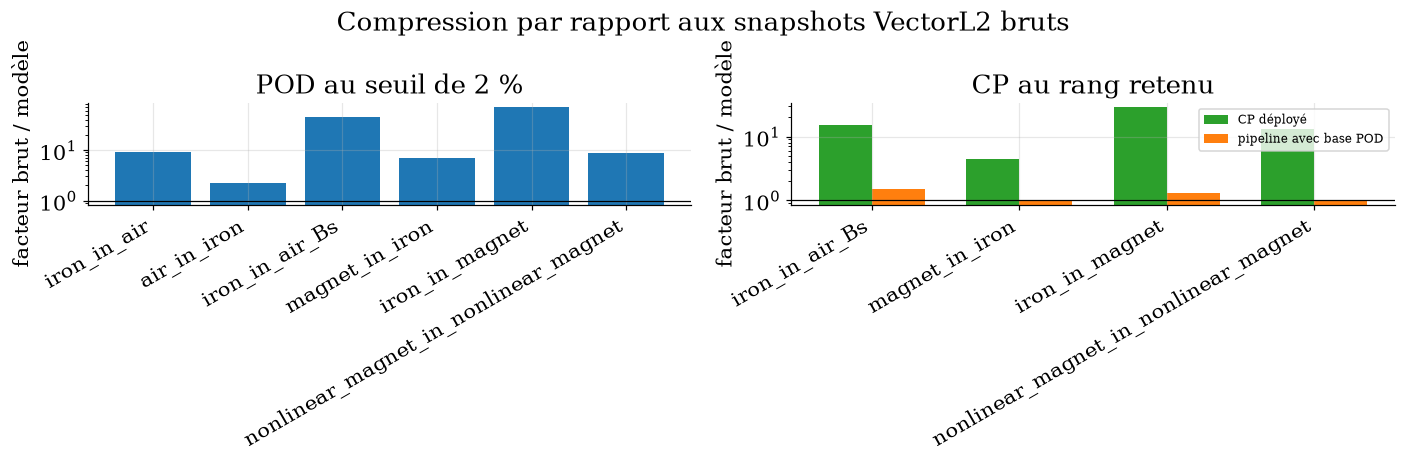

In [18]:
NEUROM_STORAGE = {
    'magnet_in_iron': (24, N_H1_FREE + len(B_ANGULAR) + len(THETA_ANGULAR)),
    'iron_in_magnet': (12, N_H1_FREE + len(B_ANGULAR) + len(THETA_ANGULAR)),
    'iron_in_air (B0 seul)': (2, N_H1_FREE + len(B_SINGLE)),
}
print('NeuROM | R | stockage H1 | brut VectorL2 | facteur indicatif')
for name, (rank, per_mode) in NEUROM_STORAGE.items():
    P = len(B_SINGLE) if name.startswith('iron_in_air') else (
        len(B_ANGULAR) * len(THETA_ANGULAR))
    raw = N_VEC * P
    store = rank * per_mode
    print(name, '|', rank, '|', store, '|', raw, '|', f'{raw/store:.1f}')

names = [row['case'] for row in STORAGE_ROWS]
x = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(x, [row['pod_factor'] for row in STORAGE_ROWS],
            color='tab:blue')
axes[0].axhline(1., color='black', lw=.8)
axes[0].set(yscale='log', ylabel='facteur brut / modèle',
            title='POD au seuil de 2 %')
axes[0].set_xticks(x, names, rotation=30, ha='right')

cp_rows = [row for row in STORAGE_ROWS if 'cp_r' in row]
y = np.arange(len(cp_rows))
width = .36
axes[1].bar(y-width/2, [row['cp_factor'] for row in cp_rows],
            width, label='CP déployé', color='tab:green')
axes[1].bar(y+width/2,
            [row['cp_pipeline_factor'] for row in cp_rows],
            width, label='pipeline avec base POD', color='tab:orange')
axes[1].axhline(1., color='black', lw=.8)
axes[1].set(yscale='log', ylabel='facteur brut / modèle',
            title='CP au rang retenu')
axes[1].set_xticks(y, [row['case'] for row in cp_rows],
                  rotation=30, ha='right')
axes[1].legend(fontsize=8)
fig.suptitle('Compression par rapport aux snapshots VectorL2 bruts')
fig.tight_layout()
plt.show()


### 5.6 Contrôle hors grille élargi des six bases spatiales

Les points hors grille sont résolus à nouveau par NGSolve. Nous projetons ces champs sur les modes POD calculés avec la grille fine, dans la norme $M$ de l'élément fini :

$$
\widehat q_r=\Phi_r\Phi_r^\top Mq,\qquad
e(q)=\frac{\lVert q-\widehat q_r\rVert_M}{\lVert q\rVert_M}.
$$

Ce test mesure donc la capacité de la base spatiale à représenter de nouveaux champs. Il ne teste pas l'interpolation des coefficients paramétriques : ceux-ci sont recalculés par la projection optimale pour chaque nouveau champ. La campagne élargie utilise **32 points par cas**, générés avec un échantillonnage Latin hypercube pseudo-aléatoire reproductible (`seed=20260916`). Pour les paramètres angulaires, les points sont tirés sur $[0,2\pi)$ sans recopier $2\pi$, qui est le même angle que $0$. Les points qui coïncideraient avec un nœud de la grille d'apprentissage sont décalés ; dans cette campagne, aucun rejet n'a été nécessaire.

Le nombre de 32 points est un compromis entre une statistique plus informative et le coût des résolutions EF supplémentaires. Les statistiques rapportées sont le maximum, la moyenne, la médiane et le 95e percentile des 32 erreurs. Elles décrivent la couverture de l'échantillon ; elles ne constituent pas une borne uniforme sur tout le domaine paramétrique.


iron_in_air                                | r5%=  1 | max=0.04% | moy=0.03% | médiane=0.03% | p95=0.04%
iron_in_air                                | r2%=  1 | max=0.04% | moy=0.03% | médiane=0.03% | p95=0.04%
air_in_iron                                | r5%=  3 | max=14.78% | moy=6.50% | médiane=5.63% | p95=13.48%
air_in_iron                                | r2%=  4 | max=6.29% | moy=2.95% | médiane=2.35% | p95=6.08%
iron_in_air_Bs                             | r5%=  1 | max=0.04% | moy=0.02% | médiane=0.03% | p95=0.04%
iron_in_air_Bs                             | r2%=  1 | max=0.04% | moy=0.02% | médiane=0.03% | p95=0.04%
magnet_in_iron                             | r5%= 11 | max=18.88% | moy=5.23% | médiane=4.82% | p95=7.64%
magnet_in_iron                             | r2%= 20 | max=10.33% | moy=2.97% | médiane=2.64% | p95=4.83%
iron_in_magnet                             | r5%=  2 | max=0.04% | moy=0.03% | médiane=0.03% | p95=0.04%
iron_in_magnet                             | r2%=  

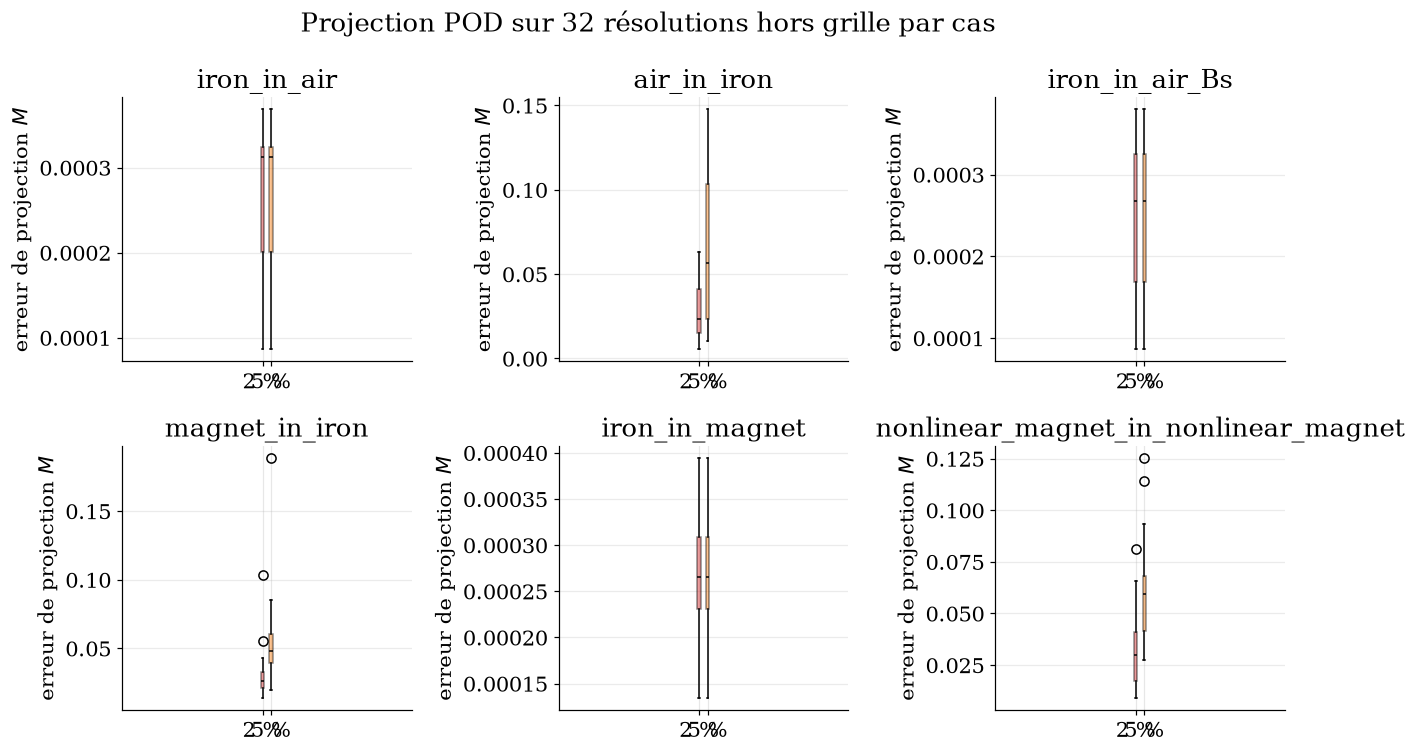

In [19]:
def projection_error(ref, Phi):
    projection = Phi @ (Phi.T @ mass_product(ref))
    return float(l2_norm(ref - projection) / l2_norm(ref))

def error_statistics(errors):
    errors = np.asarray(errors, dtype=float)
    return {'max': float(np.max(errors)), 'mean': float(np.mean(errors)),
            'median': float(np.median(errors)), 'p95': float(np.percentile(errors, 95))}

# [R3_POD] Statistiques de projection sur 32 points hors grille par cas.
OUTSIDE_STATS = {}
for case in STUDY_CASES:
    OUTSIDE_STATS[case] = {}
    for tol in (.05, .02):
        rank = STUDY_PODS[case][2][tol]
        Phi = STUDY_PODS[case][3][:, :rank]
        stats = error_statistics([projection_error(ref, Phi) for ref in OUTSIDE_REFS[case]])
        OUTSIDE_STATS[case][tol] = {'rank': rank, **stats}
        print(f"{case:42s} | r{tol:.0%}={rank:3d} | "
              f"max={stats['max']:.2%} | moy={stats['mean']:.2%} | "
              f"médiane={stats['median']:.2%} | p95={stats['p95']:.2%}")
print(f'campagne hors grille : {len(STUDY_CASES)} x {HOLDOUT_COUNT} points | seed={HOLDOUT_SEED}')

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=False)
for ax, case in zip(axes.flat, STUDY_CASES):
    for tol, color in ((.05, 'tab:orange'), (.02, 'tab:red')):
        rank = OUTSIDE_STATS[case][tol]['rank']
        Phi = STUDY_PODS[case][3][:, :rank]
        errors = [projection_error(ref, Phi) for ref in OUTSIDE_REFS[case]]
        ax.boxplot(errors, positions=[tol], widths=.012, orientation='vertical',
                   patch_artist=True, boxprops={'facecolor': color, 'alpha': .45},
                   medianprops={'color': 'black'})
    ax.set(title=case, xticks=[.05, .02], xticklabels=['5 %', '2 %'],
           ylabel='erreur de projection $M$')
    ax.grid(True, axis='y', alpha=.25)
fig.suptitle('Projection POD sur 32 résolutions hors grille par cas')
fig.tight_layout()
plt.show()


### 5.7 Prédiction CP/PARAFAC hors grille

La reconstruction CP de la section précédente était mesurée sur les snapshots de la grille d'apprentissage. Elle vérifiait la compression du tenseur, mais pas encore une prédiction entre paramètres. Nous ajoutons ici ce test sur les **mêmes 32 points hors grille** et avec les mêmes références `OUTSIDE_REFS` que pour la POD.

Pour chaque cas multiparamétrique, nous retenons le rang CP qui atteint 2\% sur la grille fine ; lorsque ce seuil n'est pas atteint, nous retenons le dernier rang calculé. Les facteurs spatiaux sont conservés, tandis que chaque facteur paramétrique est interpolé axe par axe : interpolation linéaire pour $B_0$ et $B_s$, interpolation périodique pour les angles. Le tenseur CP prédit alors un tenseur de coefficients dans la base POD, qui est reconstruit en champ par multiplication par cette base. L'erreur est mesurée dans la norme $M$ du champ complet.

Ce protocole ajoute donc une hypothèse d'interpolation et peut révéler une difficulté absente de la simple reconstruction des snapshots. Les quatre statistiques (maximum, moyenne, médiane et percentile 95) décrivent l'échantillon de 32 points ; elles ne constituent pas une borne uniforme.


iron_in_air_Bs                             | R= 3 | CP grille=1.00% | max=77.21% | moy=10.07% | médiane=2.65% | p95=34.81% | ALS convergée=True


magnet_in_iron                             | R=32 | CP grille=1.73% | max=13.94% | moy=5.05% | médiane=4.82% | p95=8.15% | ALS convergée=False
iron_in_magnet                             | R= 5 | CP grille=1.06% | max=30.81% | moy=2.68% | médiane=1.44% | p95=7.32% | ALS convergée=True


nonlinear_magnet_in_nonlinear_magnet       | R=24 | CP grille=10.33% | max=391.34% | moy=45.06% | médiane=23.24% | p95=159.40% | ALS convergée=False


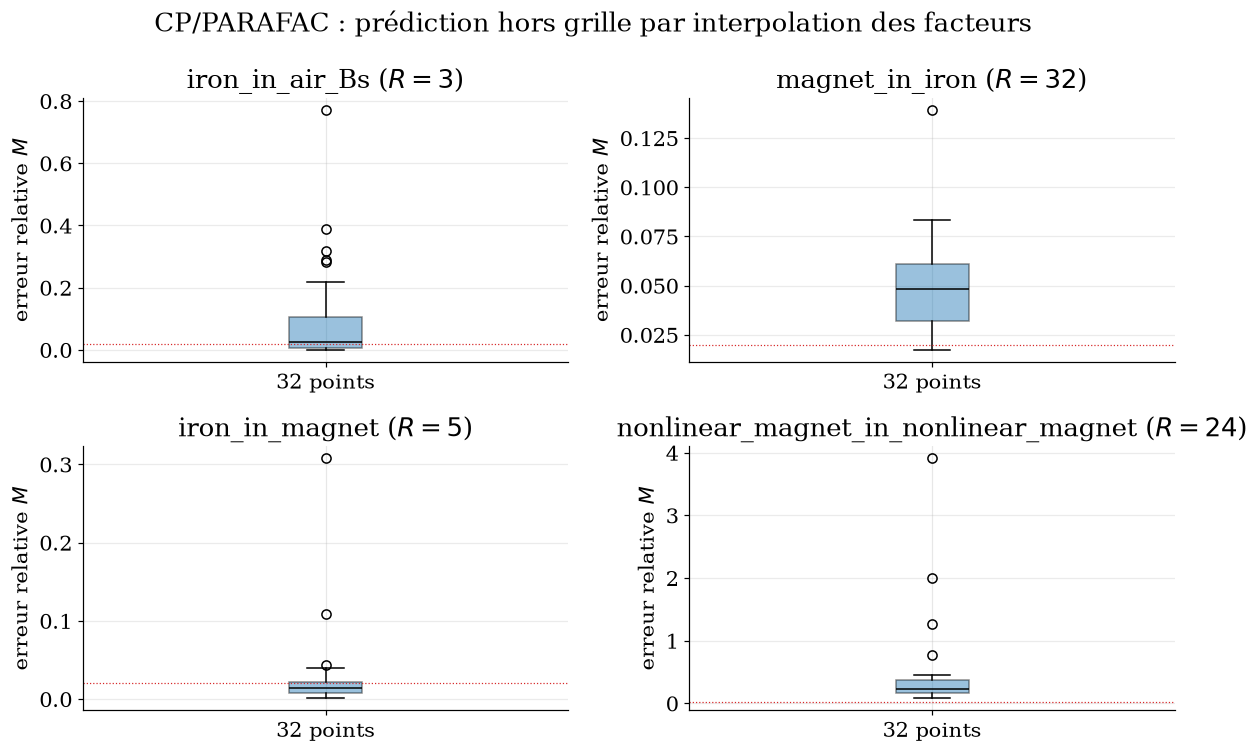


Contrôle identité CP aux nœuds de grille :
iron_in_air_Bs                             | max mismatch interpolation-vs-tenseur=3.169e-14


magnet_in_iron                             | max mismatch interpolation-vs-tenseur=2.750e-14


iron_in_magnet                             | max mismatch interpolation-vs-tenseur=2.324e-15


nonlinear_magnet_in_nonlinear_magnet       | max mismatch interpolation-vs-tenseur=1.245e-15

Points de maximum CP et norme M de la référence :
iron_in_air_Bs                             | point=(2.240976176135694, 1.333165271090313) | erreur=77.21% | ||q_ref||M=4.121e-02 (médiane=1.153e+00) | médiane erreur=2.65% | p95=34.81%
magnet_in_iron                             | point=(0.9264284530312694, 0.10835588824992129) | erreur=13.94% | ||q_ref||M=8.490e-01 (médiane=1.984e+00) | médiane erreur=4.82% | p95=8.15%
iron_in_magnet                             | point=(1.6696108387578357, 6.244658041812348) | erreur=30.81% | ||q_ref||M=9.503e-02 (médiane=1.682e+00) | médiane erreur=1.44% | p95=7.32%
nonlinear_magnet_in_nonlinear_magnet       | point=(2.860073814418441, 3.9991266354194837, 1.8700997933332784) | erreur=391.34% | ||q_ref||M=3.938e-01 (médiane=4.118e+00) | médiane erreur=23.24% | p95=159.40%


In [20]:
# [R4_CP] Interpolation hors grille des facteurs CP et contrôles associés.
def interp_factor(axis, values, x, periodic=False):
    """Interpole un facteur CP, avec raccord explicite pour un angle périodique."""
    axis = np.asarray(axis, dtype=float)
    values = np.asarray(values, dtype=float)
    x = float(x)
    if periodic:
        period = 2*np.pi
        x = x % period
        xp = np.r_[axis, period]
        fp = np.vstack((values, values[0]))
        return np.array([np.interp(x, xp, fp[:, r]) for r in range(values.shape[1])])
    return np.array([np.interp(x, axis, values[:, r]) for r in range(values.shape[1])])

def cp_fit_with_factors(case, rank, n_init=3, max_iter=300, tol=1e-8):
    """Ajuste le CP sur les coefficients POD et conserve le meilleur tenseur."""
    label = P_LEVEL_LABELS[case][-1]
    info = P_CONVERGENCE[case]['levels'][label]
    Phi, MS = info['Phi'], info['MS']
    dims = tuple(len(axis) for axis in STUDY_AXES_FINE[case])
    C = (Phi.T @ MS).reshape((Phi.shape[1],) + dims)
    starts = [('svd', None)] + [('random', 123 + j) for j in range(n_init-1)]
    best = None
    for init, seed in starts:
        actual = init if (init != 'svd' or rank <= min(C.shape)) else 'random'
        cp, errors = parafac(C, rank=rank, init=actual,
                             random_state=seed if actual == 'random' else None,
                             n_iter_max=max_iter, tol=tol,
                             normalize_factors=False, return_errors=True)
        fit = float(np.linalg.norm(C-cp_to_tensor(cp)) / max(np.linalg.norm(C), 1e-30))
        if best is None or fit < best['fit']:
            best = {'cp': cp, 'fit': fit, 'iterations': len(errors),
                    'converged': len(errors) < max_iter}
    return best

def cp_predict_field(cp, case, point, Phi):
    """Prédit q à un point paramétrique par interpolation des facteurs CP."""
    factors = cp.factors
    weights = np.asarray(cp.weights, dtype=float)
    coeff = np.zeros(factors[0].shape[0])
    for r in range(len(weights)):
        amplitude = weights[r] * factors[0][:, r].copy()
        for j, (axis, periodic) in enumerate(zip(STUDY_AXES_FINE[case],
                                                   P_PERIODIC_AXES[case])):
            value = interp_factor(axis, factors[j+1], point[j], periodic)[r]
            amplitude *= value
        coeff += amplitude
    return Phi @ coeff

CP_INTERP_RESULTS = {}
for case in CP_CASES:
    fine_rows = CP_RESULTS[case][P_LEVEL_LABELS[case][-1]]
    selected = next((row['rank'] for row in fine_rows if row['error'] <= .02), None)
    selected = selected if selected is not None else fine_rows[-1]['rank']
    fit = cp_fit_with_factors(case, selected)
    Phi = P_CONVERGENCE[case]['levels'][P_LEVEL_LABELS[case][-1]]['Phi']
    errors = [l2_norm(ref-cp_predict_field(fit['cp'], case, point, Phi))/l2_norm(ref)
              for point, ref in zip(OUTSIDE[case], OUTSIDE_REFS[case])]
    stats = error_statistics(errors)
    CP_INTERP_RESULTS[case] = {'rank': selected, 'fit': fit['fit'], 'cp': fit['cp'], **stats,
                               'errors': errors, 'iterations': fit['iterations'],
                               'converged': fit['converged']}
    print(f"{case:42s} | R={selected:2d} | CP grille={fit['fit']:.2%} | "
          f"max={stats['max']:.2%} | moy={stats['mean']:.2%} | "
          f"médiane={stats['median']:.2%} | p95={stats['p95']:.2%} | "
          f"ALS convergée={fit['converged']}")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=False)
for ax, case in zip(axes.flat, CP_CASES):
    result = CP_INTERP_RESULTS[case]
    ax.boxplot(result['errors'], patch_artist=True,
               boxprops={'facecolor': 'tab:blue', 'alpha': .45},
               medianprops={'color': 'black'})
    ax.axhline(.02, color='tab:red', ls=':', lw=.8)
    ax.set(title=f"{case} ($R={result['rank']}$)",
           xticks=[1], xticklabels=['32 points'], ylabel='erreur relative $M$')
    ax.grid(True, axis='y', alpha=.25)
fig.suptitle('CP/PARAFAC : prédiction hors grille par interpolation des facteurs')
fig.tight_layout()
plt.show()


# Contrôle de cohérence : aux nœuds d'apprentissage, l'interpolation des
# facteurs doit reproduire le tenseur CP reconstruit (à la précision numérique).
print('\nContrôle identité CP aux nœuds de grille :')
CP_NODE_MISMATCH = {}
for case in CP_CASES:
    result = CP_INTERP_RESULTS[case]
    cp = result['cp']
    Phi = P_CONVERGENCE[case]['levels'][P_LEVEL_LABELS[case][-1]]['Phi']
    coeff_tensor = cp_to_tensor(cp)
    mismatches = []
    for index in product(*[range(len(axis)) for axis in STUDY_AXES_FINE[case]]):
        point = tuple(float(STUDY_AXES_FINE[case][j][index[j]])
                      for j in range(len(index)))
        coeff = coeff_tensor[(slice(None),) + index]
        field_tensor = Phi @ coeff
        field_interp = cp_predict_field(cp, case, point, Phi)
        denom = max(l2_norm(field_tensor), 1e-30)
        mismatches.append(l2_norm(field_interp - field_tensor) / denom)
    CP_NODE_MISMATCH[case] = float(np.max(mismatches))
    print(f'{case:42s} | max mismatch interpolation-vs-tenseur=' 
          f'{CP_NODE_MISMATCH[case]:.3e}')

print('\nPoints de maximum CP et norme M de la référence :')
CP_WORST = {}
for case in CP_CASES:
    result = CP_INTERP_RESULTS[case]
    i = int(np.argmax(result['errors']))
    norms = np.array([l2_norm(ref) for ref in OUTSIDE_REFS[case]])
    CP_WORST[case] = {'point': OUTSIDE[case][i], 'error': float(result['errors'][i]),
                      'norm_ref': float(norms[i]), 'median_norm_ref': float(np.median(norms)),
                      'p95_error': result['p95'], 'median_error': result['median']}
    print(f"{case:42s} | point={CP_WORST[case]['point']} | "
          f"erreur={CP_WORST[case]['error']:.2%} | ||q_ref||M="
          f"{CP_WORST[case]['norm_ref']:.3e} (médiane={np.median(norms):.3e}) | "
          f"médiane erreur={result['median']:.2%} | p95={result['p95']:.2%}")


## 6. NeuROM a priori : une intégration minimale et testable

La section 5 étudie la séparabilité après calcul des snapshots EF. Nous passons à une représentation séparée apprise directement par NeuROM, sans injecter ces snapshots dans la loss. Deux cas à paramètres $(B_0,\theta_m)$ testent la périodicité et l'ordre des matériaux, puis un contrôle plus simple utilise seulement $B_0$.

Les cellules gardent le même rythme : une idée ou une équation est suivie du morceau de code qui la réalise. La grille de loss, les références EF hors grille et les diagnostics sont séparés.


### POD *a posteriori* et PGD *a priori*

Pour chaque paramètre $\mu$, le solveur EF produit un champ $q_{\mathrm{EF}}(x,\mu)$. Avec $P$ snapshots en colonnes, la POD cherche

$$S \simeq \Phi C, \qquad S \in \mathbb{R}^{N\times P}, \quad \Phi \in \mathbb{R}^{N\times r}$$

Elle comprime donc des solutions **déjà calculées**. La colonne $C_{:,j}$ reste attachée au point de grille $\mu_j$ : avec plusieurs paramètres, elle ne devient pas automatiquement un produit de fonctions séparées.

La PGD impose cette structure **avant** de calculer la solution. NeuROM représente le correcteur scalaire $K$, le champ physique étant $q = \operatorname{curl}K$ :

$$K_R(x,B_0,\theta_m) = \sum_{r=1}^{R} X_r(x)\,F_r(B_0)\,G_r(\theta_m)$$

$$q_R(x,B_0,\theta_m) = \operatorname{curl}K_R = \sum_{r=1}^{R} \operatorname{curl}X_r(x)\,F_r(B_0)\,G_r(\theta_m)$$

Le rang $R$ compte les produits séparés. Ce n'est ni le rang de la SVD spatiale de la section 5, ni une suite unique de valeurs singulières dès qu'il y a plusieurs axes paramétriques.

Références : [Kolda & Bader (2009)](https://doi.org/10.1137/07070111X), [De Lathauwer, De Moor & Vandewalle (2000)](https://doi.org/10.1137/S0895479896305696), [Chinesta, Ladevèze & Cueto (2011)](https://doi.org/10.1007/s11831-011-9064-7).

### Pourquoi NeuROM ici ?

NeuROM fournit les modes, le `forward` espace-paramètres, `InterpPara`, `AddMode`, `UnfreezeTruncated` et `AddMode2Optimizer`. NGSolve reste responsable de la base $H^1$, des dérivées et de la quadrature. Les facteurs sont appris en minimisant une énergie dont la stationnarité redonne la forme faible du correcteur.

Les snapshots servent à la section 5 ; les grilles paramétriques servent aux loss ; les 32 résolutions EF déjà calculées par cas servent au contrôle hors grille POD, CP et NeuROM. Une faible loss ne garantit pas à elle seule une faible erreur de champ, et un petit rang POD ne fournit pas automatiquement les facteurs NeuROM. Les tableaux donnent donc erreur hors grille, rang, stockage et temps.


### 6.1 Contrat de maillage et limites de l'API

La classe NeuROM attend un maillage issu de son contrat NeuROM/Gmsh : elle
cherche notamment les degrés de liberté, les nœuds, la connectivité et
`ListOfDirichletsBCsValues`. Un objet `ngsolve.Mesh` ne fournit pas ce contrat.
La cellule suivante essaie donc l'appel direct et conserve l'erreur attendue
comme information de reproductibilité.

La routine stock `Training_NeuROM` cible des énergies mécaniques ; elle ne sait
pas former la loi $B$--$H$ du fer ni la contribution de l'aimant. Nous utilisons
néanmoins les briques NeuROM génériques et écrivons seulement l'adaptateur
nécessaire entre la base NGSolve et la loss magnétostatique.

In [21]:
try:
    NeuROM(STUDY_MESH, [torch.tensor([0., 1., 2.])],
           {'solver': {'IntegralMethod': 'Gaussian_quad'}},
           n_modes_ini=1, n_modes_max=1)
except AttributeError as exc:
    print('API directe NeuROM/ngsolve.Mesh : échec attendu ->', exc)
    print('Le petit adaptateur H1 est donc nécessaire.')
else:
    raise AssertionError('Le test direct devait échouer avec ngsolve.Mesh.')

API directe NeuROM/ngsolve.Mesh : échec attendu -> 'ngsolve.comp.Mesh' object has no attribute 'ListOfDirichletsBCsValues'
Le petit adaptateur H1 est donc nécessaire.


#### 6.1.1 Construire les opérateurs locaux NGSolve

Le correcteur $K$ appartient à une base scalaire $H^1_0(\Omega)$. Pour éviter
de reconstruire une matrice globale à chaque itération, on préassemble les
évaluations de chaque fonction de base et de ses deux dérivées aux points de
quadrature. `VALUE_OP`, `DX_OP` et `DY_OP` sont des matrices creuses qui
transforment les 1783 coefficients libres en valeurs locales.

La cellule suivante réalise uniquement cette traduction NGSolve vers PyTorch ;
elle ne contient encore ni facteur paramétrique ni entraînement.

In [22]:
# Opérateurs H1/curl NGSolve évalués sur une règle de quadrature.
ir_neurom = ng.IntegrationRule(ng.ET.TRIG, 4)
FREE_NEUROM = np.flatnonzero(np.asarray(H1_STUDY.FreeDofs(), dtype=bool))
FREE_MAP_NEUROM = -np.ones(H1_STUDY.ndof, dtype=int)
FREE_MAP_NEUROM[FREE_NEUROM] = np.arange(len(FREE_NEUROM))
N_FREE_NEUROM, N_VECTOR_NEUROM = len(FREE_NEUROM), int(VL2.ndof)

def build_h1_quad_ops(mesh, fes):
    rows, cols, value, dx, dy = [], [], [], [], []
    coords, weights, inside = [], [], []
    q = 0
    for element in mesh.Elements():
        fe, dofs = fes.GetFE(element), fes.GetDofNrs(element)
        trafo = mesh.GetTrafo(element)
        for ip in ir_neurom:
            mip = trafo(ip)
            coords.append((float(mip.point[0]), float(mip.point[1])))
            weights.append(float(mip.measure * ip.weight))
            inside.append(str(element.mat) == 'inc')
            shape, dshape = fe.CalcShape(mip), fe.CalcDShape(mip)
            for local, global_dof in enumerate(dofs):
                free_dof = FREE_MAP_NEUROM[global_dof]
                if free_dof >= 0:
                    rows.append(q)
                    cols.append(free_dof)
                    value.append(float(shape[local]))
                    dx.append(float(dshape[local, 0]))
                    dy.append(float(dshape[local, 1]))
            q += 1
    def sparse(vals):
        ij = torch.tensor([rows, cols], dtype=torch.long)
        return torch.sparse_coo_tensor(
            ij, torch.tensor(vals), (q, N_FREE_NEUROM),
            check_invariants=False).coalesce()
    return sparse(value), sparse(dx), sparse(dy), torch.tensor(coords), \
        torch.tensor(weights), torch.tensor(inside)

VALUE_OP, DX_OP, DY_OP, QUAD_XY, QUAD_W, QUAD_INC = \
    build_h1_quad_ops(STUDY_MESH, H1_STUDY)

def snapshot_to_quad(ref):
    """Évalue un snapshot déjà calculé sur les mêmes points de quadrature."""
    FIELD.vec.FV().NumPy()[:] = np.asarray(ref)
    values = np.asarray(FIELD(STUDY_MESH(QUAD_XY[:, 0].numpy(), QUAD_XY[:, 1].numpy())))
    return values.reshape(len(QUAD_W), 2)

def outside_quad_refs(case):
    return np.asarray([snapshot_to_quad(ref) for ref in OUTSIDE_REFS[case]])


#### 6.1.2 Un mode spatial compatible avec NeuROM

NeuROM doit pouvoir appeler un objet spatial et optimiser ses coefficients. La
classe ci-dessous stocke un vecteur de coefficients $H^1$, évalue le mode avec
`VALUE_OP` et calcule

$$
\operatorname{curl}K=(\partial_yK,-\partial_xK)
$$

avec `DY_OP` et `DX_OP`. Les méthodes `Freeze_FEM`, `UnFreeze_FEM` et les
méthodes de maillage sont les petits points d'interface attendus par la classe
stock ; le maillage lui-même reste celui de NGSolve.

In [23]:
class NGSolveSpatialMode(nn.Module):
    def __init__(self, mesh, n_components=2):
        super().__init__()
        self.coeff = nn.Parameter(torch.zeros(N_FREE_NEUROM))
        self.coordinates = nn.ParameterList([])
        self.IdStored, self.Stored_ID = False, {}
    def forward(self, x=None, *args):
        return torch.sparse.mm(VALUE_OP, self.coeff[:, None])
    def curl(self):
        dx = torch.sparse.mm(DX_OP, self.coeff[:, None]).squeeze(1)
        dy = torch.sparse.mm(DY_OP, self.coeff[:, None]).squeeze(1)
        return torch.stack((dy, -dx), 1)
    def SetBCs(self, values): pass
    def Freeze_Mesh(self): pass
    def UnFreeze_Mesh(self): pass
    def Freeze_FEM(self): self.coeff.requires_grad = False
    def UnFreeze_FEM(self): self.coeff.requires_grad = True
    def ZeroOut(self): self.coeff.data.zero_()
    def StoreIdList(self, x):
        self.Stored_ID = {'coordinates': x, 'Ids': None}
        self.IdStored = True

#### 6.1.3 Un facteur angulaire périodique

L'angle vit sur un cercle : il faut imposer

$$
G(\theta+2\pi)=G(\theta).
$$

Une interpolation linéaire ordinaire traiterait 0 et $2\pi$ comme deux bords
distincts. `PeriodicInterpPara` replie d'abord l'angle modulo $2\pi$, puis
interpole le dernier nœud avec le premier. Les deux extrémités représentent
ainsi la même configuration physique sans paramètre dupliqué.

In [24]:
class PeriodicInterpPara(nn.Module):
    def __init__(self, mu_min, mu_max, N_mu):
        super().__init__()
        self.N_mu, self.period = int(N_mu), 2*np.pi
        self.coordinates = nn.ParameterList([])
        self.InterpoLayer = nn.Linear(self.N_mu, 1, bias=False)
        self.InterpoLayer.weight.data.fill_(1.)
    def forward(self, mu):
        x = torch.as_tensor(mu, dtype=self.InterpoLayer.weight.dtype).reshape(-1)
        t = torch.remainder(x, self.period) * (self.N_mu / self.period)
        i0, frac = torch.floor(t).long().remainder(self.N_mu), t - t.floor()
        w = self.InterpoLayer.weight[0]
        return ((1-frac)*w[i0] + frac*w[(i0+1).remainder(self.N_mu)]).reshape(-1, 1)
    def Freeze_Mesh(self): pass
    def UnFreeze_Mesh(self): pass
    def Freeze_FEM(self): self.InterpoLayer.weight.requires_grad = False
    def UnFreeze_FEM(self): self.InterpoLayer.weight.requires_grad = True
    def ZeroOut(self): self.InterpoLayer.weight.data.zero_()

class FakeMesh:
    dimension = '2'
    ListOfDirichletsBCsValues = []

#### 6.1.4 Assembler le modèle NeuROM

Le constructeur reçoit deux axes : neuf valeurs de $B_0$ et seize nœuds angulaires. Pour l'axe $B_0$, on conserve l'interpolation NeuROM standard ; pour l'angle, on injecte l'interpolateur périodique défini juste au-dessus.

Le budget est centralisé dans `R_MAX`. Ici il vaut 24, et la même valeur est passée à `n_modes_max` afin que le modèle et la boucle d'enrichissement aient la même capacité. La cellule vérifie aussi la forme du `forward` sur la grille cartésienne.

In [25]:
def make_model(seed=43, n_modes_max=24):
    torch.manual_seed(seed)
    np.random.seed(seed)
    old_mesh, old_interp = neurom_pde.MeshNN_2D, neurom_pde.InterpPara
    def interpolation(a, b, n):
        if abs(float(a)) < 1e-12 and abs(float(b)-2*np.pi) < 1e-12:
            return PeriodicInterpPara(a, b, n)
        neurom_pde.InterpPara = old_interp
        try:
            return old_interp(a, b, n)
        finally:
            neurom_pde.InterpPara = interpolation
    try:
        neurom_pde.MeshNN_2D, neurom_pde.InterpPara = NGSolveSpatialMode, interpolation
        return NeuROM(
            FakeMesh(),
            [torch.tensor([float(B_ANGULAR.min()), float(B_ANGULAR.max()), len(B_ANGULAR)]),
             torch.tensor([0., 2*np.pi, len(THETA_ANGULAR)])],
            {'solver': {'IntegralMethod': 'Gaussian_quad'}},
            n_modes_ini=1, n_modes_max=n_modes_max)
    finally:
        neurom_pde.MeshNN_2D, neurom_pde.InterpPara = old_mesh, old_interp

R_MAX, EPOCHS = 24, 30
model = make_model(43, n_modes_max=R_MAX)
standard = model.forward(
    QUAD_XY,
    [torch.tensor(B_ANGULAR, dtype=QUAD_W.dtype)[:, None],
     torch.tensor(THETA_ANGULAR, dtype=QUAD_W.dtype)[:, None]],
)
print('NeuROM.forward standard grille :', tuple(standard.shape),
      '| H1 libres=', N_FREE_NEUROM, '| VectorL2=', N_VECTOR_NEUROM)


NeuROM.forward standard grille : (5496, 1, 9, 16) | H1 libres= 1783 | VectorL2= 5496


### 6.2 Pourquoi une énergie physique ?

**Le problème à résoudre.** Jusqu'ici, la démarche est *a posteriori* : on calcule d'abord les $P$ solutions EF, puis on les comprime. Mais si le but est d'**éviter** ces résolutions, comprimer après coup ne fait économiser aucun calcul. La PGD veut apprendre la forme séparée *a priori*, sans jamais construire les snapshots.

Il faut donc un critère à minimiser qui **ne mentionne aucune solution de référence**. L'énergie le fournit.

Notons $\Omega$ le domaine tronqué, $\omega \subset \Omega$ l'inclusion et $K \in H^1_0(\Omega)$ le correcteur. Le champ corrigé et le champ total sont

$$q = \operatorname{curl}K = (\partial_y K,\,-\partial_x K), \qquad b = b_0 + q, \qquad b_0(B_0) = (B_0,\,0)$$

Dans l'aimant, $m(\theta_m) = M(\cos\theta_m,\,\sin\theta_m)$ ; hors de l'inclusion, $m = 0$. La loi constitutive dérive d'un potentiel, $h = \partial W/\partial b$ :

$$h_{\mathrm{out}}(b) = \nu_{\mathrm{out}}(|b|)\,b, \qquad h_{\mathrm{in}}(b) = \nu_0 b - m(\theta_m)$$

#### 6.2.1 Fonctionnelle relative et forme faible

**Le point de départ : la loi dérive d'un potentiel.** Les deux lois de comportement s'écrivent $h = \partial W/\partial b$, avec

$$W_{\mathrm{out}}(b)=\int_{0}^{|b|}\nu_{\mathrm{out}}(s)\,s\,\mathrm{d}s,
\qquad W_{\mathrm{in}}(b)=\tfrac{1}{2}\nu_0|b|^2-b\cdot m(\theta_m)$$

C'est la seule hypothèse nécessaire, et elle tient ici parce que $\nu$ ne dépend que de $|b|$ (loi radiale) et que l'aimantation est constante. Avec de l'hystérésis ou une anisotropie non intégrable, $W$ n'existerait pas et toute cette construction tomberait.

**L'énergie relative.** On pose, pour $\mu=(B_0,\theta_m)$,

$$\Pi_\mu(K)=\int_{\Omega}\Big[\underbrace{W_\mu(b_0+\operatorname{curl}K)}_{(a)}-\underbrace{W_\mu(b_0)}_{(b)}-\underbrace{h_{\mathrm{out}}(b_0)\cdot\operatorname{curl}K}_{(c)}\Big]\,\mathrm{d}x$$

**La dérivée directionnelle.** Par définition, la variation de $\Pi_\mu$ en $K$ dans la direction $\varphi$ est

$$\delta\Pi_\mu(K;\varphi)=\lim_{t\to 0}\frac{\Pi_\mu(K+t\varphi)-\Pi_\mu(K)}{t}$$

Elle se calcule terme à terme. Comme $K\mapsto\operatorname{curl}K$ est **linéaire**, on a $b(K+t\varphi)=b(K)+t\operatorname{curl}\varphi$ avec $b=b_0+\operatorname{curl}K$, et la règle de la chaîne donne pour $(a)$ :

$$\frac{\mathrm{d}}{\mathrm{d}t}\Big|_{t=0}W_\mu\big(b+t\operatorname{curl}\varphi\big)
=\underbrace{\frac{\partial W_\mu}{\partial b}(b)}_{=\;h_\mu(b)}\cdot\operatorname{curl}\varphi$$

Le terme $(b)$ ne dépend pas de $K$ : sa dérivée est nulle. Le terme $(c)$ est linéaire en $K$ : sa dérivée est lui-même. D'où

$$\delta\Pi_\mu(K;\varphi)=\int_{\Omega}\operatorname{curl}\varphi\cdot\big[h_\mu(b_0+\operatorname{curl}K)-h_{\mathrm{out}}(b_0)\big]\,\mathrm{d}x$$

**Le rôle de chaque terme** se lit alors directement :

| terme | dérivée | rôle |
|---|---|---|
| $(a)$ | $h_\mu(b)\cdot\operatorname{curl}\varphi$ | le terme recherché |
| $(b)$ | $0$ | rend $\Pi_\mu$ **finie** : sans lui, l'intégrande tend vers $W_\mu(b_0)\neq 0$ loin de l'inclusion, sur un domaine immense |
| $(c)$ | $-h_{\mathrm{out}}(b_0)\cdot\operatorname{curl}\varphi$ | produit le **second membre** |

**Retour à la forme faible.** On annule la variation pour toute fonction test $\varphi$, puis on ajoute et retranche $h_\mu(b_0)$ dans le crochet :

$$h_\mu(b)-h_{\mathrm{out}}(b_0)=\underbrace{\big[h_\mu(b)-h_\mu(b_0)\big]}_{\text{membre de gauche}}+\underbrace{\big[h_\mu(b_0)-h_{\mathrm{out}}(b_0)\big]}_{\text{nul hors de }\omega}$$

Le second crochet vaut $h_{\mathrm{in}}(b_0)-h_{\mathrm{out}}(b_0)$ dans $\omega$ et **s'annule à l'extérieur**, où $h_\mu=h_{\mathrm{out}}$. Il ne reste que

$$\int_{\Omega}\operatorname{curl}\varphi\cdot\big[h_\mu(b_0+\operatorname{curl}K)-h_\mu(b_0)\big]\,\mathrm{d}x
=-\int_{\omega}\operatorname{curl}\varphi\cdot\big[h_{\mathrm{in}}(b_0)-h_{\mathrm{out}}(b_0)\big]\,\mathrm{d}x$$

soit exactement la forme faible assemblée par NGSolve en section 3. Choisir $h_{\mathrm{out}}(b_0)$ plutôt que $h_\mu(b_0)$ dans $(c)$ n'est donc pas arbitraire : c'est la seule expression **valable partout**, ce qui permet d'écrire $\Pi_\mu$ comme une intégrale unique et fait ressortir le saut de matériau tout seul.

**Conséquence.** Minimiser $\Pi_\mu$ équivaut à résoudre l'équation du correcteur — sans jamais calculer de solution de référence. L'apprentissage optimise le même équilibre physique que le solveur, sur chaque couple de paramètres.

> $\Pi_\mu$ est une **énergie, pas une erreur** : elle vaut $0$ en $K=0$, on la minimise, elle devient donc négative. Sa valeur n'a pas d'échelle absolue et ne se compare pas à un pourcentage de champ — d'où les contrôles $L^2$ hors grille.


#### 6.2.2 Quadrature de l'énergie et construction du champ

La fonction $W_{\mathrm{out}}$ n'est pas intégrée symboliquement. Pour un champ
de norme $|b|$, on évalue l'intégrale radiale

$$
W_{\mathrm{out}}(b)=\int_0^{|b|}\nu_{\mathrm{out}}(s)s\,\mathrm{d}s
$$

par huit points de Gauss-Legendre. La première cellule de code définit cette
quadrature et les deux lois d'énergie. La seconde cellule combine ensuite les
modes spatiaux et les facteurs NeuROM :

$$
q_R(x_j,B_0,\theta_m)=\sum_{r=1}^{R}
\operatorname{curl}X_r(x_j)\,F_r(B_0)\,G_r(\theta_m).
$$

`qv` est donc le champ physique aux points $x_j$ ; les snapshots n'interviennent
à aucun moment dans ce calcul.

In [26]:
z, w = np.polynomial.legendre.leggauss(8)
Z, W = torch.tensor((z+1)/2), torch.tensor(w/2)
def nu_torch(s2):
    r = (s2/B_SAT**2)**(ALPHA/2)
    return NU_FE + (NU0-NU_FE)*r/(1+r)
def W_out(b):
    s = torch.sqrt((b*b).sum(-1)+1e-24)
    sr = Z.view(1, 1, -1)*s[..., None]
    return (W.view(1, 1, -1)*nu_torch(sr*sr)*sr*s[..., None]).sum(-1)

La fonction `curl_quadrature` utilise `Para_modes` pour les facteurs et
`Space_modes` pour les modes $H^1$. Elle ne remplace pas `NeuROM.forward` : elle
ajoute seulement l'opération spécifique dont la loss a besoin, à savoir le curl
évalué aux points de quadrature plutôt que le champ brut du réseau.

In [27]:
def curl_quadrature(model, B, theta):
    B = torch.as_tensor(B, dtype=QUAD_W.dtype).reshape(-1, 1)
    theta = torch.as_tensor(theta, dtype=QUAD_W.dtype).reshape(-1, 1)
    factors = torch.stack([
        model.Para_modes[m][0](B).squeeze(1)
        * model.Para_modes[m][1](theta).squeeze(1)
        for m in range(int(model.n_modes_truncated))
    ], 1)
    modes = torch.stack([
        model.Space_modes[m].curl()
        for m in range(int(model.n_modes_truncated))
    ], 2)
    return torch.einsum('qcm,pm->pqc', modes, factors)

#### 6.2.3 Assembler la loss discrète

Si $x_j$ sont les points de quadrature et $w_j$ leurs poids avec la mesure de
l'élément, l'intégrale devient

$$
\Pi_\mu^h(K)=\sum_{j=1}^{N_q}w_j\,\mathcal{E}_\mu(x_j;K).
$$

Dans l'inclusion, le code écrit le contraste sous la forme

$$
W_{\mathrm{in}}(b)-W_{\mathrm{in}}(b_0)-h_{\mathrm{out}}(b_0)\cdot q
=
W_{\mathrm{in}}(b)-W_{\mathrm{in}}(b_0)-h_{\mathrm{in}}(b_0)\cdot q
+\left(h_{\mathrm{in}}(b_0)-h_{\mathrm{out}}(b_0)\right)\cdot q.
$$

C'est la décomposition des lignes `ein` et `eout`. `QUAD_INC` sélectionne la
formule intérieure ou extérieure à chaque point. Les matrices creuses donnent
les valeurs de $K$ et de ses dérivées, puis la moyenne sur les 144 couples est
la quantité différentiée par Adam :

$$
\mathcal{L}(\Theta)=\frac{1}{|\mathcal{G}|}
\sum_{\mu\in\mathcal{G}}\Pi_\mu^h\left(K_R(\,\cdot\,,\mu;\Theta)\right),
\qquad |\mathcal{G}|=9\times16=144.
$$

La cellule suivante ne fait donc qu'évaluer cette loss vectorisée ; elle ne
contient ni une comparaison avec un snapshot ni une nouvelle résolution EF.

In [28]:
# [R5_NEUROM] Énergie physique discrète pour AP dans le fer.
def physics_energy(model, B, theta):
    B = torch.as_tensor(B, dtype=QUAD_W.dtype).reshape(-1)
    theta = torch.as_tensor(theta, dtype=QUAD_W.dtype).reshape(-1)
    qv = curl_quadrature(model, B, theta)
    b0 = torch.stack((B, B*0), 1)[:, None, :]
    mvec = torch.stack((M_REM*torch.cos(theta), M_REM*torch.sin(theta)), 1)[:, None, :]
    h0 = nu_torch((b0*b0).sum(-1))[..., None]*b0
    hi = NU0*b0-mvec
    b = b0+qv
    Win = .5*NU0*(b*b).sum(-1)-(b*mvec).sum(-1)
    Win0 = .5*NU0*(b0*b0).sum(-1)-(b0*mvec).sum(-1)
    eout = W_out(b)-W_out(b0)-(h0*qv).sum(-1)
    ein = Win-Win0-(hi*qv).sum(-1)+((hi-h0)*qv).sum(-1)
    return (QUAD_W[None, :]*torch.where(QUAD_INC[None, :], ein, eout)).sum()/len(B)

### 6.3 Quel budget de rang tester ?

Le premier test NeuROM vérifiait le raccord entre les modes spatiaux NGSolve, les facteurs paramétriques, `AddMode`, `UnfreezeTruncated` et l'énergie. Un rang faible ne constitue pas une borne théorique. Le pilote principal conserve un budget jusqu'à $R=24$ pour `magnet_in_iron`, et le second cas va jusqu'à $R=12$. Les coûts en coefficients sont reportés dans la section 5.5.

In [29]:
BT, TT = torch.meshgrid(
    torch.tensor(B_ANGULAR, dtype=QUAD_W.dtype),
    torch.tensor(THETA_ANGULAR, dtype=QUAD_W.dtype), indexing='ij')
BT, TT = BT.reshape(-1), TT.reshape(-1)
HOLDOUT = OUTSIDE['magnet_in_iron']
REF_QUAD = outside_quad_refs('magnet_in_iron')
def quad_error(pred, ref):
    wq = QUAD_W.numpy()[:, None]
    return float(np.sqrt((wq*(pred-ref)**2).sum()/(wq*ref**2).sum()))

print('grille apprentissage=', len(BT), '| holdout EF partagé=', len(HOLDOUT))


grille apprentissage= 144 | holdout EF partagé= 32


**Enrichissement progressif.** On ajoute les modes un par un. À chaque rang $R$, le maillage est gelé (`Freeze_Mesh`) et Adam optimise les seuls coefficients des modes :

$$\min_{\{X_r,F_r,G_r\}_{r\le R}} \; \frac{1}{|\mathcal{G}|}\sum_{\mu\in\mathcal{G}} \Pi_\mu^h(K_R)$$

Après chaque rang, on mesure l'erreur $L^2$ sur les 32 points hors grille partagés avec la POD et l'on vérifie la périodicité en comparant $\theta=0$ et $\theta=2\pi$.

In [30]:
# [R5_NEUROM] Enrichissement en rang et évaluation hors grille.
def train_rank_enrichment(model, energy_fn, B_grid, theta_grid,
                          holdout, ref_quad, r_max, epochs):
    rows, optimizer = [], None
    ttrain = time.perf_counter()
    for rank in range(1, r_max + 1):
        if rank > 1:
            model.AddMode()
            model.UnfreezeTruncated()
            model.Freeze_Mesh()
            model.Freeze_MeshPara()
            model.AddMode2Optimizer(optimizer)
        else:
            model.UnfreezeTruncated()
            model.Freeze_Mesh()
            model.Freeze_MeshPara()
            optimizer = torch.optim.Adam(
                [p for p in model.parameters() if p.requires_grad], lr=.02)
        history = []
        for _ in range(epochs):
            optimizer.zero_grad()
            loss = energy_fn(model, B_grid, theta_grid)
            loss.backward()
            optimizer.step()
            history.append(float(loss.detach()))
        with torch.no_grad():
            pred = curl_quadrature(
                model, [p[0] for p in holdout], [p[1] for p in holdout]).numpy()
        errors = np.array([quad_error(pred[i], ref_quad[i])
                           for i in range(len(holdout))])
        storage = rank * (N_FREE_NEUROM + len(B_ANGULAR) + len(THETA_ANGULAR))
        rows.append((rank, history[-1], errors.max(), errors.mean(),
                     np.median(errors), np.percentile(errors, 95), storage))
    train_time = time.perf_counter() - ttrain
    periodic_gap = float(torch.abs(
        curl_quadrature(model, [1.37, 1.37], [0., 2*np.pi])[0]
        - curl_quadrature(model, [1.37, 1.37], [0., 2*np.pi])[1]).max().detach())
    for rank, loss, emax, emean, emedian, ep95, storage in rows:
        print(f'rang {rank}: loss={loss:.5e} | '
              f'holdout max/moy/médiane/p95={emax:.2%}/{emean:.2%}/'
              f'{emedian:.2%}/{ep95:.2%} | stockage={storage}')
    print(f'NeuROM R={r_max} seed=43 | apprentissage={train_time:.2f} s | '
          f'périodicité gap={periodic_gap:.3e}')
    return rows, train_time, periodic_gap

rows, train_time, periodic_gap = train_rank_enrichment(
    model, physics_energy, BT, TT, HOLDOUT, REF_QUAD, R_MAX, EPOCHS)


rang 1: loss=-8.99449e-01 | holdout max/moy/médiane/p95=163.54%/89.15%/92.47%/125.86% | stockage=1808
rang 2: loss=-1.30697e+00 | holdout max/moy/médiane/p95=110.33%/70.41%/71.95%/101.58% | stockage=3616
rang 3: loss=-1.41231e+00 | holdout max/moy/médiane/p95=110.13%/65.51%/65.58%/104.47% | stockage=5424
rang 4: loss=-2.02782e+00 | holdout max/moy/médiane/p95=116.04%/42.67%/39.43%/71.99% | stockage=7232
rang 5: loss=-2.18602e+00 | holdout max/moy/médiane/p95=66.39%/21.06%/18.00%/35.65% | stockage=9040
rang 6: loss=-2.19903e+00 | holdout max/moy/médiane/p95=78.55%/20.77%/15.94%/38.70% | stockage=10848
rang 7: loss=-2.20440e+00 | holdout max/moy/médiane/p95=71.37%/17.81%/13.07%/33.24% | stockage=12656
rang 8: loss=-2.20684e+00 | holdout max/moy/médiane/p95=64.49%/16.46%/13.17%/29.59% | stockage=14464
rang 9: loss=-2.20891e+00 | holdout max/moy/médiane/p95=67.52%/15.69%/12.47%/29.43% | stockage=16272
rang 10: loss=-2.20920e+00 | holdout max/moy/médiane/p95=67.37%/15.42%/11.56%/30.33% | st

### 6.4 Lire le résultat du budget élargi

Le tableau imprimé par la boucle donne, pour chaque rang, la loss finale, les quatre statistiques d'erreur sur les 32 points hors grille partagés avec la POD et le nombre de coefficients. Les nombres de stockage utilisent neuf valeurs de $B_0$ et seize valeurs angulaires, soit $1783+9+16=1808$ coefficients par mode. Les sorties sont calculées avec la campagne élargie de 32 points.

Le maximum hors grille n'est pas nécessairement monotone avec le rang, car chaque rang est optimisé avec le budget Adam fixé. La moyenne, la médiane et le percentile 95 donnent une lecture plus stable de la distribution.


### 6.5 Second cas : `iron_in_magnet`

Le cas `iron_in_magnet` inverse l'ordre des matériaux : le fer non linéaire est dans l'inclusion et l'aimant uniforme est à l'extérieur. Il conserve les deux paramètres $B_0$ et $\theta_m$, donc le même interpolateur périodique, la même base $H^1$ et la grille fine $9\times16$.

La section 5 annonce une famille bien plus simple (POD de rang $2$ contre $20$). La construction NeuROM n'est pas dupliquée : seules la densité d'énergie par matériau et la référence EF changent.

In [31]:
def physics_energy_iron_in_magnet(model, B, theta):
    B = torch.as_tensor(B, dtype=QUAD_W.dtype).reshape(-1)
    theta = torch.as_tensor(theta, dtype=QUAD_W.dtype).reshape(-1)
    qv = curl_quadrature(model, B, theta)
    b0 = torch.stack((B, B*0), 1)[:, None, :]
    mvec = torch.stack((M_REM*torch.cos(theta), M_REM*torch.sin(theta)), 1)[:, None, :]
    h0 = NU0*b0 - mvec
    b = b0 + qv
    W_iron, W_iron0 = W_out(b), W_out(b0)
    W_mag = .5*NU0*(b*b).sum(-1) - (b*mvec).sum(-1)
    W_mag0 = .5*NU0*(b0*b0).sum(-1) - (b0*mvec).sum(-1)
    e_in = W_iron - W_iron0 - (h0*qv).sum(-1)
    e_out = W_mag - W_mag0 - (h0*qv).sum(-1)
    return (QUAD_W[None, :] * torch.where(QUAD_INC[None, :], e_in, e_out)).sum()/len(B)

HOLDOUT_IRON_MAGNET = OUTSIDE['iron_in_magnet']
REF_QUAD_IRON_MAGNET = outside_quad_refs('iron_in_magnet')
print('second case holdout EF partagé=', len(HOLDOUT_IRON_MAGNET))


second case holdout EF partagé= 32


Le code précédent ne change que la référence constitutive : dans l'inclusion,
`W_out` représente maintenant le fer ; à l'extérieur, l'énergie de l'aimant est
linéaire. La condition stationnaire reste la même, et la fonction générique
`train_rank_enrichment` est réutilisée sans copier la boucle PGD.

Pour garder le notebook raisonnable, ce second cas est testé jusqu'à
$R_{second}=12$ avec le même seed et 30 époques par rang. Ce n'est pas un rang
optimal ; c'est un contrôle de transfert vers l'ordre de matériaux opposé.

In [32]:
# [R5_NEUROM] Cas inverse : fer dans un aimant permanent.
R_SECOND = 12
model_iron_magnet = make_model(43, n_modes_max=R_SECOND)
rows_iron_magnet, time_iron_magnet, gap_iron_magnet = train_rank_enrichment(
    model_iron_magnet, physics_energy_iron_in_magnet, BT, TT,
    HOLDOUT_IRON_MAGNET, REF_QUAD_IRON_MAGNET, R_SECOND, EPOCHS)

rang 1: loss=-6.84532e-01 | holdout max/moy/médiane/p95=429.06%/95.27%/93.59%/117.19% | stockage=1808
rang 2: loss=-9.42434e-01 | holdout max/moy/médiane/p95=143.43%/75.16%/85.53%/102.53% | stockage=3616
rang 3: loss=-9.90613e-01 | holdout max/moy/médiane/p95=257.01%/76.17%/82.45%/103.34% | stockage=5424
rang 4: loss=-1.67309e+00 | holdout max/moy/médiane/p95=746.39%/44.39%/15.70%/75.95% | stockage=7232
rang 5: loss=-1.74523e+00 | holdout max/moy/médiane/p95=216.63%/14.35%/6.43%/24.63% | stockage=9040
rang 6: loss=-1.74969e+00 | holdout max/moy/médiane/p95=174.49%/11.13%/4.48%/21.41% | stockage=10848
rang 7: loss=-1.74996e+00 | holdout max/moy/médiane/p95=165.53%/10.75%/4.52%/20.00% | stockage=12656
rang 8: loss=-1.75052e+00 | holdout max/moy/médiane/p95=157.53%/10.14%/4.34%/18.81% | stockage=14464
rang 9: loss=-1.75064e+00 | holdout max/moy/médiane/p95=150.26%/9.83%/4.45%/18.00% | stockage=16272
rang 10: loss=-1.75030e+00 | holdout max/moy/médiane/p95=162.49%/10.40%/4.48%/17.98% | sto

Le tableau de sortie permet de comparer directement ce cas à `magnet_in_iron`. Les références sont les champs déjà calculés dans `OUTSIDE_REFS`, avec l'ordre de matériaux correspondant à ce cas ; la périodicité est contrôlée par `gap_iron_magnet`. La grille NeuROM contient neuf valeurs de $B_0$ et seize angles. Le stockage par mode est donc $1783+9+16=1808$ coefficients.

Les sorties de la cellule précédente donnent, pour les 32 mêmes points hors grille, le maximum, la moyenne, la médiane et le percentile 95 à chaque rang. Le rang 12 reste seulement le budget fixé pour ce second pilote : il ne prétend pas être optimal.


### 6.6 Contrôle à un seul paramètre : `iron_in_air`

Pour le fer non linéaire dans l'air, la symétrie élimine l'angle : le correcteur dépend seulement de $B_0$,

$$
q_R(x,B_0)=\sum_{r=1}^R\operatorname{curl}X_r(x)F_r(B_0).
$$

Un mode contient $1783$ coefficients $H^1$ libres et neuf valeurs de $F_r$, soit $1792$ coefficients. Nous testons $R=1,\ldots,4$ : ce budget suffit pour voir si l'erreur continue à baisser dans un cas dont la POD spatiale est déjà de rang 1.

In [33]:
class B0MeshProxy(FakeMesh):
    def GetCellIds(self, x):
        # NGSolveSpatialMode évalue déjà avec VALUE_OP ; cet appel ne sert
        # qu'à satisfaire l'interface du forward gaussien de NeuROM.
        return np.zeros(len(x), dtype=np.int32)

def make_model_b0(seed=43, n_modes_max=4):
    torch.manual_seed(seed)
    np.random.seed(seed)
    old_mesh, old_interp = neurom_pde.MeshNN_2D, neurom_pde.InterpPara
    try:
        neurom_pde.MeshNN_2D = NGSolveSpatialMode
        neurom_pde.InterpPara = old_interp
        model = NeuROM(
            B0MeshProxy(),
            [torch.tensor([
                float(B_SINGLE.min()), float(B_SINGLE.max()), len(B_SINGLE)
            ])],
            {'solver': {'IntegralMethod': 'Gaussian_quad'}},
            n_modes_ini=1,
            n_modes_max=n_modes_max,
        )
    finally:
        neurom_pde.MeshNN_2D, neurom_pde.InterpPara = old_mesh, old_interp

    for mode in model.Space_modes:
        mode.mesh = B0MeshProxy()
    return model


#### 6.6.1 Champ séparé et énergie

La quadrature et la base spatiale ne changent pas ; `curl_quadrature_b0` retire seulement le facteur angulaire. Dans l'inclusion, la primitive est celle du fer ; à l'extérieur, $W_{\mathrm{air}}(b)=\nu_0|b|^2/2$. La référence commune est la loi extérieure $h_0=\nu_0b_0$. La densité relative est

$$
W_j(b_0+q)-W_j(b_0)-h_0\cdot q,
\qquad j\in\{\mathrm{fer},\mathrm{air}\}.
$$

Sa dérivée par rapport à $q$ donne $h_j(b_0+q)-h_0$, le contraste de la forme faible. Sans angle, il n'y a pas de condition de périodicité.


In [34]:
def curl_quadrature_b0(model, B):
    B = torch.as_tensor(B, dtype=QUAD_W.dtype).reshape(-1, 1)
    factors = torch.stack([
        model.Para_modes[m][0](B).squeeze(1)
        for m in range(int(model.n_modes_truncated))
    ], dim=1)
    modes = torch.stack([
        model.Space_modes[m].curl()
        for m in range(int(model.n_modes_truncated))
    ], dim=2)
    return torch.einsum('qcm,pm->pqc', modes, factors)

def physics_energy_iron_in_air_b0(model, B):
    B = torch.as_tensor(B, dtype=QUAD_W.dtype).reshape(-1)
    qv = curl_quadrature_b0(model, B)
    b0 = torch.stack((B, B*0), dim=1)[:, None, :]
    h0 = NU0*b0                         # air reference law
    b = b0 + qv

    W_iron, W_iron0 = W_out(b), W_out(b0)
    W_air = .5*NU0*(b*b).sum(-1)
    W_air0 = .5*NU0*(b0*b0).sum(-1)

    # In the inclusion, the common reference h0 is recovered by adding the
    # contrast hi-h0. Outside, the material is air.
    e_in = W_iron - W_iron0 - (h0*qv).sum(-1)
    e_out = W_air - W_air0 - (h0*qv).sum(-1)
    return (QUAD_W[None, :]
            * torch.where(QUAD_INC[None, :], e_in, e_out)).sum()/len(B)


#### 6.6.2 Apprentissage et contrôle hors grille

Les neuf valeurs `B_SINGLE` servent à la loss. Les 32 points `OUTSIDE['iron_in_air']` sont exactement ceux du contrôle POD et leurs références sont réutilisées via `OUTSIDE_REFS`. La boucle reprend l'enrichissement NeuROM et Adam, avec 100 époques par rang. Ce cas peu coûteux permet de distinguer un manque de rang d'une optimisation trop courte.


In [35]:
# [R5_NEUROM] Contrôle à un paramètre : fer dans l'air.
B0_GRID = torch.tensor(B_SINGLE, dtype=QUAD_W.dtype)
HOLDOUT_B0 = OUTSIDE['iron_in_air']
REF_QUAD_B0 = outside_quad_refs('iron_in_air')

def train_rank_enrichment_b0(model, energy_fn, B_grid,
                             holdout, ref_quad, r_max=4, epochs=100):
    rows, optimizer = [], None
    ttrain = time.perf_counter()
    n_b = len(B_grid)
    for rank in range(1, r_max + 1):
        if rank > 1:
            model.AddMode()
            # AddMode crée un nouveau mode spatial sans l'attribut attendu par
            # le forward gaussien ; il n'est pas appelé dans la loss, mais on
            # le complète pour que le modèle reste inspectable.
            model.Space_modes[-1].mesh = B0MeshProxy()
            model.UnfreezeTruncated()
            model.Freeze_Mesh()
            model.Freeze_MeshPara()
            model.AddMode2Optimizer(optimizer)
        else:
            model.UnfreezeTruncated()
            model.Freeze_Mesh()
            model.Freeze_MeshPara()
            optimizer = torch.optim.Adam(
                [p for p in model.parameters() if p.requires_grad], lr=.02)

        for _ in range(epochs):
            optimizer.zero_grad()
            loss = energy_fn(model, B_grid)
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            pred = curl_quadrature_b0(
                model, [p[0] for p in holdout]).numpy()
        errors = np.array([quad_error(pred[i], ref_quad[i])
                           for i in range(len(holdout))])
        storage = rank * (N_FREE_NEUROM + n_b)
        rows.append((rank, float(loss.detach()), errors.max(), errors.mean(),
                     np.median(errors), np.percentile(errors, 95), storage))

    train_time = time.perf_counter() - ttrain
    for rank, loss, emax, emean, emedian, ep95, storage in rows:
        print(f'B0 rang {rank}: loss={loss:.5e} | '
              f'holdout max/moy/médiane/p95={emax:.2%}/{emean:.2%}/'
              f'{emedian:.2%}/{ep95:.2%} | stockage={storage}')
    print(f'B0 NeuROM R={r_max} seed=43 | '
          f'apprentissage={train_time:.2f} s')
    return rows, train_time

MODEL_B0 = make_model_b0(43, n_modes_max=4)
ROWS_B0, TIME_B0 = train_rank_enrichment_b0(
    MODEL_B0, physics_energy_iron_in_air_b0, B0_GRID,
    HOLDOUT_B0, REF_QUAD_B0, r_max=4, epochs=100)


B0 rang 1: loss=-4.22801e-01 | holdout max/moy/médiane/p95=24.49%/4.00%/2.22%/9.54% | stockage=1792
B0 rang 2: loss=-4.22814e-01 | holdout max/moy/médiane/p95=24.54%/3.68%/2.08%/8.84% | stockage=3584
B0 rang 3: loss=-4.22878e-01 | holdout max/moy/médiane/p95=24.46%/3.19%/1.67%/8.75% | stockage=5376
B0 rang 4: loss=-4.22878e-01 | holdout max/moy/médiane/p95=24.39%/3.20%/1.71%/8.75% | stockage=7168
B0 NeuROM R=4 seed=43 | apprentissage=6.41 s


### 6.7 Comparaison NeuROM sur le même échantillon

Les trois modèles entraînés ci-dessus sont maintenant évalués sur les mêmes 32 points que la POD et la CP, avec les références déjà stockées dans `OUTSIDE_REFS`. Cette comparaison évite de confondre un changement de modèle avec un changement de jeu de test. Les valeurs sont des erreurs de champ évaluées par quadrature, et non des erreurs de projection POD.


In [36]:
def neurom_stats(pred, refs):
    errors = np.array([quad_error(pred[i], refs[i]) for i in range(len(refs))])
    return {'max': float(errors.max()), 'mean': float(errors.mean()),
            'median': float(np.median(errors)),
            'p95': float(np.percentile(errors, 95)), 'errors': errors}

# [R5_NEUROM] Tableau final sur les 32 points partagés.
NEUROM_OUTSIDE_STATS = {}
with torch.no_grad():
    refs = outside_quad_refs('magnet_in_iron')
    pred = curl_quadrature(model,
                           [p[0] for p in OUTSIDE['magnet_in_iron']],
                           [p[1] for p in OUTSIDE['magnet_in_iron']]).numpy()
    NEUROM_OUTSIDE_STATS['magnet_in_iron'] = neurom_stats(pred, refs)
    refs = outside_quad_refs('iron_in_magnet')
    pred = curl_quadrature(model_iron_magnet,
                           [p[0] for p in OUTSIDE['iron_in_magnet']],
                           [p[1] for p in OUTSIDE['iron_in_magnet']]).numpy()
    NEUROM_OUTSIDE_STATS['iron_in_magnet'] = neurom_stats(pred, refs)
    refs = outside_quad_refs('iron_in_air')
    pred = curl_quadrature_b0(MODEL_B0,
                              [p[0] for p in OUTSIDE['iron_in_air']]).numpy()
    NEUROM_OUTSIDE_STATS['iron_in_air'] = neurom_stats(pred, refs)

for case, result in NEUROM_OUTSIDE_STATS.items():
    print(f"{case:42s} | max={result['max']:.2%} | "
          f"moy={result['mean']:.2%} | médiane={result['median']:.2%} | "
          f"p95={result['p95']:.2%}")


print('\nPoints de maximum NeuROM et norme quadrature de la référence :')
NEUROM_WORST = {}
for case, result in NEUROM_OUTSIDE_STATS.items():
    i = int(np.argmax(result['errors']))
    refs = outside_quad_refs(case)
    wq = QUAD_W.numpy()[:, None]
    norms = np.array([float(np.sqrt((wq * ref**2).sum())) for ref in refs])
    NEUROM_WORST[case] = {'point': OUTSIDE[case][i], 'error': float(result['errors'][i]),
                         'norm_ref': float(norms[i]), 'median_norm_ref': float(np.median(norms)),
                         'p95_error': result['p95'], 'median_error': result['median']}
    print(f"{case:42s} | point={NEUROM_WORST[case]['point']} | "
          f"erreur={NEUROM_WORST[case]['error']:.2%} | ||q_ref||Q="
          f"{NEUROM_WORST[case]['norm_ref']:.3e} (médiane={np.median(norms):.3e}) | "
          f"médiane erreur={result['median']:.2%} | p95={result['p95']:.2%}")


magnet_in_iron                             | max=51.52% | moy=11.24% | médiane=7.00% | p95=30.48%
iron_in_magnet                             | max=122.08% | moy=7.70% | médiane=3.09% | p95=14.05%
iron_in_air                                | max=24.39% | moy=3.20% | médiane=1.71% | p95=8.75%

Points de maximum NeuROM et norme quadrature de la référence :
magnet_in_iron                             | point=(0.9264284530312694, 0.10835588824992129) | erreur=51.52% | ||q_ref||Q=8.490e-01 (médiane=1.984e+00) | médiane erreur=7.00% | p95=30.48%
iron_in_magnet                             | point=(1.6696108387578357, 6.244658041812348) | erreur=122.08% | ||q_ref||Q=9.503e-02 (médiane=1.681e+00) | médiane erreur=3.09% | p95=14.05%


iron_in_air                                | point=(3.164323891440133,) | erreur=24.39% | ||q_ref||Q=6.237e-02 (médiane=7.948e-01) | médiane erreur=1.71% | p95=8.75%


La cellule précédente donne les statistiques sur les 32 points partagés. Le gain devient faible après $R=2$ et le plateau est à interpréter avec le budget Adam fixé. Ce test valide le chemin NeuROM à un paramètre ; il ne démontre pas à lui seul une compression utile, et L-BFGS reste un bonus éventuel.


## 7. Comparaison et conclusion

Le notebook suit une progression unique pour les six études : POD spatiale, convergence quand $P$ augmente, PARAFAC pour les quatre cas à plusieurs paramètres, puis contrôle hors grille. Cette organisation sépare dimension spatiale, séparation simultanée des paramètres et coût mémoire.

La figure POD contient les six cas sur la même échelle. L'étude en $P$ indique si un petit nombre de snapshots sous-estime la complexité. Le contrôle POD utilise 32 points hors grille par cas et mesure une projection optimale ; il renseigne la couverture spatiale. PARAFAC ajoute une contrainte plus forte, un produit par axe paramétrique. Son interpolation des facteurs est testée séparément sur les mêmes points : la reconstruction sur grille peut être bonne sans fournir une prédiction paramétrique fiable.

Le bilan de stockage compare enfin $NP$, $r(N+P)$, les coûts CP et les coûts NeuROM en ddl $H^1$. Ces facteurs ne sont comparables qu'en gardant à l'esprit que POD/CP stockent le champ VectorL2 tandis que NeuROM optimise une base spatiale $H^1$. Les trois évaluations NeuROM réutilisent elles aussi les 32 mêmes références. Avec le seed et les budgets retenus, l'erreur reste élevée et non monotone en rang ; cela valide l'intégration physique et périodique, mais ne suffit pas à conclure à une compression compétitive. L-BFGS, plusieurs initialisations et une étude du coût hors ligne/en ligne restent des suites possibles.
